In [1]:
import numpy as np

In [2]:
import copy
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Juego

In [4]:
class Jugador:
  def __init__(self, letra):
      self.letra = letra

### Tablero

In [5]:
class Tablero:
  def __init__(self):
      self.res_ultima_jugada=9 # Representa donde hay que jugar la próxima jugada,
                           # 9 significa jugar libre

      self.grilla= np.zeros((9,9)) # matriz del tablero grande ej:(1,3) es tablero 1 casilla 3

      self.estado_grande=np.zeros(9) # estado del tablero grande, ie como una gato normal se cambia la casilla si gano
                                     # Contiene los valores 0*/ si no se ha gandoado; 1, -1 según quien ganó y 999 para empate

  def get_grilla(self):
    return self.grilla

  def get_estado_grande(self):
    return self.estado_grande

  def get_res_ultima_jugada(self):
    return self.res_ultima_jugada

  def get_free_spaces_grande(self):
    return np.nonzero(self.estado_grande == 0)[0]

  def get_free_spaces_chico(self,i):
    return np.nonzero(self.grilla[i,:] == 0)[0]

  def espacios_libre_grande(self):
    return 0 in self.estado_grande

  def espacios_libre_chik(self,i): # i es el subtablero que quiere verificar
    return 0 in self.grilla[i,:]

  def revisar_libre_grande(self,i): # True si no ha sido ganado aun
    return self.estado_grande[i]==0

  def revisar_libre_chico(self,Des):
    return self.grilla[Des[0],Des[1]]==0


  def poner_estado(self,posicion,letra):
    if self.grilla[posicion[0]][posicion[1]]!=0:
      raise Exception("casilla ocupada")
    else:
      self.grilla[posicion[0]][posicion[1]]=letra


  def poner_estado_grande(self,posicion,letra):
    if self.estado_grande[posicion]!=0:
      raise Exception("casilla ocupada")
    else:
      self.estado_grande[posicion]=letra

  def cambiar_res_jugada(self,i):
    if self.revisar_libre_grande(i) and self.espacios_libre_chik(i): # Con 999 tampoco entra, por lo que la segunda condición puede ser optimizable si se demora luego
      self.res_ultima_jugada=i
    else:
      self.res_ultima_jugada=9



In [6]:
# # Matriz de ejemplo (3 filas x 4 columnas)
# grilla = np.array([
#     [1, 0, 3, 0],
#     [0, 5, 0, 8],
#     [7, 8, 9, 2]
# ])

# i = 1  # Evaluamos la fila 1: [0, 5, 0, 8]

# # Ejecutando la expresión:
# columnas_con_cero = np.nonzero(grilla[i, :] == 0)[0]

# print(columnas_con_cero)
# # Resultado: array([0, 2]) -> Indica que en la fila 1, las columnas 0 y 2 valen 0
# filas, columnas = np.nonzero(grilla == 0)
#       # Si quieres una lista de tuplas [(fila, col), (fila, col), ...]:
# li=list(zip(filas, columnas))

# print(li)


# columnas = np.nonzero(grilla[0, :] == 0)[0]
# # Genera la lista de tuplas fijando 'i'
# coordenadas_fila_i = [(0, col) for col in columnas]
# print([(0, col) for col in columnas])


### Juego gato

In [7]:
class Juego_gato: # Partimos del turno 1
  def __init__(self,Id_juego):
    self.id=Id_juego
    self.tablero=Tablero()
    self.jugadores=[Jugador(1),Jugador(-1)] #X = 1 e O =-1 Vamos a seguir usando la nomeclatura letra.
    self.turno=0
    self.ganador=None


  def acciones_legales(self):
    tg = self.tablero.get_res_ultima_jugada()
    if tg == 9:
        acciones = []
        for i in self.tablero.get_free_spaces_grande():
            for j in self.tablero.get_free_spaces_chico(i):
                acciones.append((int(i), int(j)))
        return acciones
    else:
        return [(int(tg), int(j))for j in self.tablero.get_free_spaces_chico(tg)]


  def gano_chiquito(self,letra,i):# i = grilla[0][:]
    #t=self.tablero.grilla # t=tablero
    t = self.tablero.grilla[i]

    objetivo = 3 * letra

    resultado =(t[0] + t[1] + t[2] == objetivo or
                t[3] + t[4] + t[5] == objetivo or
                t[6] + t[7] + t[8] == objetivo or

                t[0] + t[3] + t[6] == objetivo or
                t[1] + t[4] + t[7] == objetivo or
                t[2] + t[5] + t[8] == objetivo or

                t[0] + t[4] + t[8] == objetivo or
                t[2] + t[4] + t[6] == objetivo)

    if resultado:
      self.tablero.poner_estado_grande(i,letra)
      return True # Ganó y se termina el juego
    else:
      return False


  def quien_gano_grande(self,letra):
    t=self.tablero.estado_grande
    objetivo = 3 * letra

    resultado =( t[0] + t[1] + t[2] == objetivo or
                 t[3] + t[4] + t[5] == objetivo or
                 t[6] + t[7] + t[8] == objetivo or

                 t[0] + t[3] + t[6] == objetivo or
                 t[1] + t[4] + t[7] == objetivo or
                 t[2] + t[5] + t[8] == objetivo or

                 t[0] + t[4] + t[8] == objetivo or
                 t[2] + t[4] + t[6] == objetivo)

    if resultado:
      self.ganador=letra
      return True # Ganó y se termina el juego
    return False



  def hubo_empate_chiquito(self,i):
    if self.tablero.espacios_libre_chik(i):
      return False
    else:
      if self.tablero.revisar_libre_grande(i):
        self.tablero.poner_estado_grande(i,999)
        return True
      else:
        return False



  def hubo_empate_grande(self):
    if self.tablero.espacios_libre_grande():
      return False
    else:
      if self.quien_gano_grande(1) or self.quien_gano_grande(-1):
        return False
      else:
        self.ganador=999
        return True



  def jugar_condicionado(self,turno,Decision1):# (self,turno,Decision1):
    if self.ganador is not None:
      raise Exception("Juego ya terminado")
    if turno%2==0:
      lettra= 1
    else:
      lettra= -1
    self.turno= turno
    self.turno+=1
    if not self.tablero.espacios_libre_grande():
      raise Exception("Juego ya terminado")
    else: #Si no se ha terminado el juego
      self.tablero.cambiar_res_jugada(Decision1[1])
      if not self.tablero.revisar_libre_grande(Decision1[1]): # Tablero ya ocupado # if self.tablero.get_res_ultima_jugada()==9: #Si cumple la regla
        dispo1=self.tablero.get_free_spaces_grande()
        deci_tab=np.random.choice(dispo1)
        dispo=self.tablero.get_free_spaces_chico(deci_tab)
        deci_chik=np.random.choice(dispo)
        self.tablero.poner_estado([deci_tab, deci_chik],lettra)
        self.gano_chiquito(lettra,deci_tab)
        self.hubo_empate_chiquito(deci_tab)
        self.tablero.cambiar_res_jugada(deci_chik)
        if self.quien_gano_grande(lettra):
          return self.turno,lettra
        if self.hubo_empate_grande():
          return self.turno,999
      else: # Si no se ha terminado el tablero
        posibles=self.tablero.get_free_spaces_chico(Decision1[1])
        deci_chik=np.random.choice(posibles)

        self.tablero.poner_estado([Decision1[1], deci_chik],lettra)

        self.gano_chiquito(lettra,Decision1[1])
        self.hubo_empate_chiquito(Decision1[1])
        self.tablero.cambiar_res_jugada(deci_chik)
        if self.quien_gano_grande(lettra):
          return self.turno,lettra
        if self.hubo_empate_grande():
          return self.turno,999


  def jugar(self,turno,Decision1,Decision2): # tomar turno como ronda
    self.turno=turno
    if self.ganador is not None:
      raise Exception("Juego ya terminado")
    if not self.tablero.espacios_libre_grande(): #no hay espacios
      raise Exception("Juego ya terminado")
    else:
      if not self.tablero.revisar_libre_grande(Decision1[0]): # revisa si la decision del jugador 1 es valida
        raise Exception("Tablero ya terminado")
      else:
        if self.tablero.get_res_ultima_jugada()!=Decision1[0] and self.tablero.get_res_ultima_jugada()!=9: #si no cumple condicion tablero de la ultima jugada
          raise Exception("Jugador 1 no cumplió la regla")

        else:
          if not self.tablero.revisar_libre_chico(Decision1): #revisa la casilla para ver si esta vacio
            raise Exception("Casilla ocupada para jugador 1")
          else:
            self.turno+=1
            self.tablero.poner_estado(Decision1,self.jugadores[0].letra) #poner elección en chiquito
            self.gano_chiquito(self.jugadores[0].letra,Decision1[0]) #revisa si gano chiquito
            self.hubo_empate_chiquito(Decision1[0])
            self.tablero.cambiar_res_jugada(Decision1[1]) #cambia jugada
            if self.quien_gano_grande(self.jugadores[0].letra): #revisa si gano grande
              return self.turno,self.jugadores[0].letra #si gano grande
            if self.hubo_empate_grande():
              return self.turno,999
            else:
  ############## Juega el jugador 2
              if self.tablero.get_res_ultima_jugada()!=9 and self.tablero.get_res_ultima_jugada()!=Decision2[0]: #si cumplio la regla
                raise Exception("Jugador 2 no cumplió la regla")
              else:
                if not self.tablero.revisar_libre_grande(Decision2[0]): # Si ya se ganó el tablero
                  raise Exception("Tablero ya terminado para jugador 2")
                else:
                  if not self.tablero.revisar_libre_chico(Decision2):#si la casilla esta ocupada
                    raise Exception("Casilla ocupada para jugador 2")
                  else:
                    self.turno+=1
                    self.tablero.poner_estado(Decision2,self.jugadores[1].letra)
                    self.gano_chiquito(self.jugadores[1].letra,Decision2[0])
                    self.hubo_empate_chiquito(Decision2[0])
                    self.tablero.cambiar_res_jugada(Decision2[1])
                    if self.quien_gano_grande(self.jugadores[1].letra): #revisar si gano
                      return self.turno,self.jugadores[1].letra
                    if self.hubo_empate_grande():
                      return self.turno,999


  def jugar_solo(self,Decision1):

    if self.ganador is not None:
      raise Exception("Juego ya terminado")

    letra=self.jugadores[self.turno % 2].letra

    if not self.tablero.espacios_libre_grande(): #no hay espacios
      raise Exception("Juego ya terminado")

    if not self.tablero.revisar_libre_grande(Decision1[0]): # revisa si la decision del jugador 1 es valida
      raise Exception("Tablero ya terminado")

    # print("decision recivida: ",Decision1)
    # print("res:",self.tablero.get_res_ultima_jugada())
    if self.tablero.get_res_ultima_jugada()!=Decision1[0] and self.tablero.get_res_ultima_jugada()!=9: #si no cumple condicion tablero de la ultima jugada
      raise Exception("Jugador ", letra, " no cumplió la regla")

    if not self.tablero.revisar_libre_chico(Decision1): #revisa la casilla para ver si esta vacio
      raise Exception("Casilla ocupada para jugador 1")
    self.turno+=1
    self.tablero.poner_estado(Decision1,letra) #poner elección en chiquito
    self.gano_chiquito(letra,Decision1[0]) #revisa si gano chiquito
    self.hubo_empate_chiquito(Decision1[0])
    self.tablero.cambiar_res_jugada(Decision1[1]) #cambia jugada
    if self.quien_gano_grande(letra): #revisa si gano grande
      return self.turno,letra #si gano grande
    if self.hubo_empate_grande():
      return self.turno,999
    return self.turno,None

  def jugar_cond_decision(self,turno,Decision1):
    if self.ganador is not None:
      raise Exception("Juego ya terminado")
    if turno%2==0:
      lettra= 1
    else:
      lettra= -1
    self.turno=turno
    self.turno+=1
    if not self.tablero.espacios_libre_grande():
      raise Exception("Juego ya terminado")
    else: #Si no se ha terminado el juego
      self.tablero.cambiar_res_jugada(Decision1[1])
      if self.tablero.get_res_ultima_jugada()==9: # Tablero ya ocupado # if self.tablero.get_res_ultima_jugada()==9: #Si cumple la regla
        dispo1=self.tablero.get_free_spaces_grande()
        deci_tab=np.random.choice(dispo1)
        dispo=self.tablero.get_free_spaces_chico(deci_tab)
        deci_chik=np.random.choice(dispo)
        return self.turno,(deci_tab,deci_chik)
      else: # Si no se ha terminado el tablero
        posibles=self.tablero.get_free_spaces_chico(Decision1[1])
        deci_chik=np.random.choice(posibles)
        self.tablero.cambiar_res_jugada(deci_chik)
        return self.turno,(Decision1[1],deci_chik)




In [8]:
  # def get_grilla_tablero(self):
  #   return self.tablero.grilla

  # def get_estado_grande_tablero(self):
  #   return self.tablero.get_estado_grande()

  # def es_legal(self):



In [9]:
#print(not False)

In [10]:
class Sesion:
  def __init__(self,n_instancias):
    self.n_instancias= n_instancias
    self.juegos= [Juego_gato(i) for i in range(n_instancias)]

## **Interfaz 1:** Muestra estado del tablero

Esta interfaaz fue construida por chatGPT para la primera entrega 

In [11]:
def mostrar_tablero(juego):
    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, 9)
    ax.set_ylim(9, 0)
    ax.set_aspect("equal")
    ax.axis("off")

    # Dibujar la cuadrícula
    for i in range(10):
        grosor = 3 if i % 3 == 0 else 0.7
        ax.plot([i, i], [0, 9], color="black", lw=grosor)
        ax.plot([0, 9], [i, i], color="black", lw=grosor)

    # Dibujar X y O
    for tablero in range(9):
        for casilla in range(9):

            valor = juego.tablero.grilla[tablero, casilla]

            if valor == 0:
                continue

            fila_tab, col_tab = divmod(tablero, 3)
            fila, col = divmod(casilla, 3)

            x = col_tab * 3 + col + 0.5
            y = fila_tab * 3 + fila + 0.5

            simbolo = "X" if valor == 1 else "O"
            color = "blue" if valor == 1 else "red"

            ax.text(x, y, simbolo, fontsize=24,
                    ha="center", va="center", color=color)

    # Marcar tableros ganados o empatados
    for tablero in range(9):
        estado = juego.tablero.estado_grande[tablero]

        if estado == 0:
            continue

        fila, col = divmod(tablero, 3)
        x, y = col * 3, fila * 3

        if estado == 999:
            simbolo = "EMPATE"
            color = "gray"
            tam = 14
        else:
            simbolo = "X" if estado == 1 else "O"
            color = "blue" if estado == 1 else "red"
            tam = 60

        ax.add_patch(Rectangle(
            (x, y), 3, 3, facecolor=color, alpha=0.1
        ))

        ax.text(x + 1.5, y + 1.5, simbolo,
                fontsize=tam, color=color, alpha=0.4,
                ha="center", va="center")

    # Destacar el tablero obligatorio
    obligatorio = juego.tablero.get_res_ultima_jugada()

    if obligatorio != 9:
        fila, col = divmod(int(obligatorio), 3)

        ax.add_patch(Rectangle(
            (col * 3, fila * 3), 3, 3,
            fill=False, edgecolor="dodgerblue", linewidth=5
        ))

    plt.show()

In [12]:
# juego = Juego_gato(0)

# turno = 0

# resultado = juego.jugar_condicionado(turno, (0, 4))

# mostrar_tablero(juego)

In [13]:
# juego = Juego_gato(0)
# turno = 0

# rondas = [
#     ((0, 4), (4, 0)),
#     ((0, 1), (1, 4)),
#     ((4, 2), (2, 8)),
#     ((8, 8), (8, 0)),# Aquí gana
#     ((0, 7), (7, 0)),# lo mando a uno ganado
#     ((3, 8), (8, 6)),# juega donde quiere
#     ((8, 1), (1, 5))
# ]

# for decision1, decision2 in rondas:

#     resultado = juego.jugar(turno, decision1, decision2)

#     if resultado is None:
#         turno += 2
#     else:
#         turno = resultado[0]

#     print("Cantidad de jugadas:", turno)
#     print("Estado grande:", juego.tablero.estado_grande)
#     print("Tablero obligatorio:",
#           juego.tablero.get_res_ultima_jugada())

#     mostrar_tablero(juego)

#     if resultado is not None:
#         print("Partida terminada:", resultado)
#         break

In [14]:
# juego = Juego_gato(0)
# turno = 0

# rondas = [
#     ((0, 4), (4, 0)),
#     ((0, 1), (1, 4)),
#     ((4, 2), (2, 8)),
#     ((8, 8), (8, 0)),# Aquí gana
#     ((0, 7), (7, 0)),# lo mando a uno ganado
#     ((3, 8), (8, 6)),# juega donde quiere
#     ((8, 1), (1, 5)),# juega ilegal
#     ((6, 4), (4, 4))

# ]

# for decision1, decision2 in rondas:
#     try:
#       resultado = juego.jugar(turno, decision1, decision2)
#     except Exception as e:
#       print(e)
#       pass
#     if resultado is None:
#         turno += 2
#     else:
#         turno = resultado[0]

#     print("Cantidad de jugadas:", turno)
#     print("Estado grande:", juego.tablero.estado_grande)
#     print("Tablero obligatorio:",
#           juego.tablero.get_res_ultima_jugada())

#     mostrar_tablero(juego)

#     if resultado is not None:
#         print("Partida terminada:", resultado)
#         break

In [15]:
# juego = Juego_gato(0)
# turno = 0

# rondas = [
#     ((2, 7), (7, 0)),
#     ((0, 7), (7, 2)),
#     ((2, 0), (0, 2)),
#     ((2, 5), (5, 5)),
#     ((5, 2), (2, 4)),
#     ((4, 7), (7, 7)),
#     ((7, 6), (6, 2)),
#     ((2, 6), (6, 4)),
#     ((4, 2), (2, 1)),
#     ((1, 2), (2, 8)),
#     ((8, 8), (8, 2)),
#     ((2, 2), (2, 3)),
#     ((3, 2), (6, 6))
# ]

# for decision1, decision2 in rondas:
#     try:
#       resultado = juego.jugar(turno, decision1, decision2)
#     except Exception as e:
#       print(e)
#       pass
#     if resultado is None:
#         turno += 2
#     else:
#         turno = resultado[0]

#     print("Cantidad de jugadas:", turno)
#     print("Estado grande:", juego.tablero.estado_grande)
#     print("Tablero obligatorio:",
#           juego.tablero.get_res_ultima_jugada()+1)

#     mostrar_tablero(juego)

#     if resultado is not None:
#         print("Partida terminada:", resultado)
#         break

## **Interfaz 2:** Jugar interactivo PvP


Esta interfaz fue construida por chatGPT para la primera entrega.

In [16]:
# class InterfazGato:
#     def __init__(self):
#         self.juego = Juego_gato(0)
#         self.turno = 0
#         self.decision1 = None
#         self.terminado = False
#         self.resultado = None
#         self.mensaje = "Selecciona la jugada de X. Pulsa R para reiniciar."
#         self.fig, self.ax = plt.subplots(figsize=(9, 9))
#         self.fig.canvas.mpl_connect("button_press_event", self.click)
#         self.fig.canvas.mpl_connect("key_press_event", self.tecla)
#         self.dibujar()

#     def estado_provisional(self):
#         """Calcula la consecuencia de la X provisional SIN modificar el juego real."""
#         if self.decision1 is None:
#             return None
#         prueba = copy.deepcopy(self.juego)
#         tablero, casilla = self.decision1
#         prueba.tablero.poner_estado(self.decision1, 1)
#         prueba.gano_chiquito(1, tablero)
#         prueba.hubo_empate_chiquito(tablero)
#         prueba.tablero.cambiar_res_jugada(casilla)
#         if prueba.quien_gano_grande(1):
#             fin = 1
#         elif prueba.hubo_empate_grande():
#             fin = 999
#         else:
#             fin = None
#         return prueba.tablero.get_res_ultima_jugada(), fin

#     def terminar(self, resultado):
#         self.terminado = True
#         self.resultado = resultado[1]
#         if self.resultado == 999:
#             self.mensaje = "¡Empate general! Pulsa R para reiniciar."
#         else:
#             simbolo = "X" if self.resultado == 1 else "O"
#             self.mensaje = f"¡Ganó {simbolo}! Pulsa R para reiniciar."
#         self.decision1 = None

#     def dibujar(self):
#         ax = self.ax
#         ax.clear()
#         ax.set_xlim(0, 9)
#         ax.set_ylim(9, 0)
#         ax.set_aspect("equal")
#         ax.set_xticks([])
#         ax.set_yticks([])
#         for i in range(10):
#             ancho = 3 if i % 3 == 0 else 0.8
#             color = "black" if i % 3 == 0 else "gray"
#             ax.plot([i, i], [0, 9], color=color, lw=ancho, zorder=5)
#             ax.plot([0, 9], [i, i], color=color, lw=ancho, zorder=5)

#         for tablero in range(9):
#             ft, ct = divmod(tablero, 3)
#             for casilla in range(9):
#                 valor = self.juego.tablero.grilla[tablero, casilla]
#                 if valor not in (1, -1):
#                     continue
#                 fc, cc = divmod(casilla, 3)
#                 ax.text(ct * 3 + cc + .5, ft * 3 + fc + .5,
#                         "X" if valor == 1 else "O",
#                         fontsize=25, color="royalblue" if valor == 1 else "firebrick",
#                         ha="center", va="center", zorder=2)

#         for tablero, estado in enumerate(self.juego.tablero.estado_grande):
#             if estado == 0:
#                 continue
#             ft, ct = divmod(tablero, 3)
#             color = ("royalblue" if estado == 1 else
#                      "firebrick" if estado == -1 else "gray")
#             ax.add_patch(Rectangle((ct * 3, ft * 3), 3, 3,
#                                    facecolor=color, alpha=.12, zorder=1))
#             simbolo = ("X" if estado == 1 else
#                        "O" if estado == -1 else "EMPATE")
#             ax.text(ct * 3 + 1.5, ft * 3 + 1.5, simbolo,
#                     fontsize=70 if estado != 999 else 15,
#                     color=color, alpha=.4, weight="bold",
#                     ha="center", va="center", zorder=3)

#         obligado = self.juego.tablero.get_res_ultima_jugada()
#         if self.decision1 is not None and not self.terminado:
#             tablero, casilla = self.decision1
#             ft, ct = divmod(tablero, 3)
#             fc, cc = divmod(casilla, 3)
#             ax.text(ct * 3 + cc + .5, ft * 3 + fc + .5, "X",
#                     fontsize=25, color="gray", alpha=.65,
#                     ha="center", va="center", zorder=4)
#             obligado, _ = self.estado_provisional()

#         if not self.terminado and obligado != 9:
#             ft, ct = divmod(int(obligado), 3)
#             ax.add_patch(Rectangle((ct * 3, ft * 3), 3, 3,
#                                    fill=False, edgecolor="dodgerblue",
#                                    lw=5, zorder=6))

#         if self.terminado:
#             titulo = "Empate general" if self.resultado == 999 else (
#                 f"¡Ganó {'X' if self.resultado == 1 else 'O'}!")
#         elif self.decision1 is None:
#             titulo = "Turno de X (jugada provisional)"
#         else:
#             titulo = "Turno de O (confirmar ronda)"
#         if not self.terminado:
#             titulo += (" | Tablero libre" if obligado == 9
#                        else f" | Tablero {int(obligado) + 1}")
#         ax.set_title(titulo, fontsize=14, pad=14)
#         ax.set_xlabel(self.mensaje, fontsize=10, labelpad=10)
#         self.fig.canvas.draw_idle()

#     def click(self, event):
#         if self.terminado or event.inaxes != self.ax:
#             return
#         if event.xdata is None or event.ydata is None:
#             return
#         x, y = event.xdata, event.ydata
#         if not (0 <= x < 9 and 0 < y <= 9):
#             return
#         col, fila = int(x), int(y)
#         tablero = 3 * (fila // 3) + col // 3
#         casilla = 3 * (fila % 3) + col % 3
#         decision = (tablero, casilla)
#         T = self.juego.tablero

#         if self.decision1 is None:
#             obligado = T.get_res_ultima_jugada()
#         else:
#             obligado, _ = self.estado_provisional()

#         if obligado != 9 and tablero != obligado:
#             self.mensaje = f"Movimiento inválido: debes jugar en el tablero {obligado + 1}."
#             self.dibujar()
#             return
#         if not T.revisar_libre_grande(tablero):
#             self.mensaje = "Ese tablero pequeño ya está terminado."
#             self.dibujar()
#             return
#         if not T.revisar_libre_chico(decision) or decision == self.decision1:
#             self.mensaje = "La casilla está ocupada."
#             self.dibujar()
#             return

#         if self.decision1 is None:
#             self.decision1 = decision
#             self.mensaje = "X provisional en gris; ahora elige la jugada de O."
#             _, fin = self.estado_provisional()
#             if fin is not None:
#                 # jugar() retorna antes de usar Decision2 al terminar tras X.
#                 try:
#                     resultado = self.juego.jugar(self.turno, decision, (0, 0))
#                 except Exception as error:
#                     self.decision1 = None
#                     self.mensaje = f"Error al ejecutar jugar(): {error}"
#                 else:
#                     if resultado is not None:
#                         self.turno = resultado[0]
#                         self.terminar(resultado)
#                     else:
#                         self.mensaje = "La función jugar() no retornó el fin previsto."
#             self.dibujar()
#             return

#         respaldo = copy.deepcopy(self.juego)
#         try:
#             resultado = self.juego.jugar(self.turno, self.decision1, decision)
#         except Exception as error:
#             # La función jugar() puede modificar la grilla antes de fallar.
#             self.juego = respaldo
#             self.mensaje = f"Error de jugar(): {error}"
#             self.decision1 = None
#             self.dibujar()
#             return

#         if resultado is None:
#             self.turno += 2
#             self.decision1 = None
#             self.mensaje = "Ronda realizada. Selecciona la siguiente X."
#         else:
#             self.turno = resultado[0]
#             self.terminar(resultado)
#         self.dibujar()

#     def tecla(self, event):
#         if event.key == "r":
#             self.juego = Juego_gato(0)
#             self.turno = 0
#             self.decision1 = None
#             self.terminado = False
#             self.resultado = None
#             self.mensaje = "Nueva partida. Selecciona X."
#             self.dibujar()


In [17]:
#interfaz = InterfazGato()
#plt.show()

# Creación de IA

# Entorno/Entrenamiento PettingZoo


### imports

In [18]:
#%pip install gymnasium pettingzoo

In [19]:
import gymnasium as gym
import pettingzoo
print("gym",gym.__version__)
print("pet", pettingzoo.__version__)

gym 1.4.0
pet 1.27.0


In [20]:
from pettingzoo import AECEnv

In [21]:
from gymnasium.spaces import Discrete, Box, Dict
import functools

## Entorno juego gato
En esta sección hubo ayuda de IA (ChatGPT) para la corroboración y debuggeo del código.

In [22]:
class EntornoGato(AECEnv):

  def __init__(self):
    super().__init__()
    self.juego = Juego_gato(0)
    self.agentes=["jugador 1","jugador 2"]

  def reset(self,seed=None,options=None):
    self.juego = Juego_gato(0)

    self.agents=self.agentes[:]
    self.rewards={agente: 0 for agente in self.agents}
    self._cumulative_rewards = {agent: 0 for agent in self.agents}
    self.terminations = {agent: False for agent in self.agents}
    self.truncations = {agent: False for agent in self.agents}
    self.infos = {agent: {} for agent in self.agents}
    # self.state = {agent: NONE for agent in self.agents}
    # self.observations = {agent: NONE for agent in self.agents}
    # self.num_moves = 0
    self.agent_selection = "jugador 1"

  def step(self,action): #action debe de tener (des1,des2)
    if (self.terminations[self.agent_selection] or self.truncations[self.agent_selection]):
            self._was_dead_step(action)
            return

    agente = self.agent_selection
    self._cumulative_rewards[agente] = 0

    # Convertimos la acción
    i = int(action) // 9
    j = int(action) % 9

    # Información para identificar el error
    # print("Agente:", self.agent_selection)
    # print("Acción recibida:", action)
    # print("Decisión:", (i, j))
    # print("Subtablero obligatorio:",
    #       self.juego.tablero.get_res_ultima_jugada())
    # print("¿Acción legal?",
    #       (i, j) in self.juego.acciones_legales())

    # Ejecutamos la jugada
    turno, resultado = self.juego.jugar_solo((i,j))
    self._clear_rewards

    if resultado is not None:
      for a in self.agentes:
        self.terminations[a]=True
      if resultado==1:
        self.rewards["jugador 1"]=1
        self.rewards["jugador 2"]=-1
      elif resultado==-1:
        self.rewards["jugador 1"]=-1
        self.rewards["jugador 2"]=1
      else:
        self.rewards["jugador 1"]=0
        self.rewards["jugador 2"]=0
    #end

    if agente=="jugador 1":
      self.agent_selection="jugador 2"
    else:
      self.agent_selection="jugador 1"

    self._accumulate_rewards()


  def observe(self, agnt):
    tablero=self.juego.tablero
    grilla=tablero.get_grilla().flatten().astype(np.int32)
    estado_grande=tablero.get_estado_grande().astype(np.int32)
    res_ultima=tablero.get_res_ultima_jugada()
    jugador = 1 if agnt == "jugador 1" else -1
    observacion = np.concatenate([grilla, estado_grande, [res_ultima, jugador]]).astype(np.int32)
    mascara=np.zeros(81,dtype=np.int8)
    if (agnt==self.agent_selection and not self.terminations[agnt] and not self.truncations[agnt]):
      for i,j in self.juego.acciones_legales():
        mascara[9*i+j]=1

    return {"observation": observacion,
            "action_mask": mascara}


  @functools.cache
  def action_space(self, agent):
    return Discrete(81)


  @functools.cache
  def observation_space(self, agent):

      low = np.array(
          [-1]*81 + [-1]*9 + [0, -1],
          dtype=np.int32
      )

      high = np.array(
          [1]*81 + [999]*9 + [9, 1],
          dtype=np.int32
      )

      return Dict({
          "observation": Box(
              low=low,
              high=high,
              dtype=np.int32
          ),

          "action_mask": Box(
              low=0,
              high=1,
              shape=(81,),
              dtype=np.int8
          )
      })

In [23]:
# from pettingzoo.test import api_test

# env = EntornoGato()

# api_test(
#     env,
#     num_cycles=1000,
#     verbose_progress=True
#)

## Entrenamiento

In [24]:
#!pip install sb3-contrib

In [24]:
import glob
import os
from sb3_contrib import MaskablePPO
from sb3_contrib.common.maskable.policies import MaskableActorCriticPolicy
from sb3_contrib.common.wrappers import ActionMasker

In [ ]:
# def mascara_fn(env):
#   return env.action_mask()
# def entrena_mascara(env_id,steps=10000,seed=0,):
#   env=EntonoGato()
#   env=SB3ActionMaskWrapper(env)

### Adaptador gym con enotrno
En esta sección también hubo ayuda de IA (ChatGPT) en la corroboración y debuggeo del código.

In [26]:
class GatoParaSB3(gym.Env):

    def __init__(self):
        super().__init__()
        self.env = EntornoGato()
        self.agente_ia = "jugador 1"
        self.oponente = "jugador 2"

        # Espacios definidos anteriormente en PettingZoo
        self.action_space = self.env.action_space(self.agente_ia)

        self.observation_space = (self.env.observation_space(self.agente_ia)["observation"])


    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.env.reset(seed=seed)
        obs = self.env.observe(self.agente_ia)["observation"]
        return obs, {}


    def action_masks(self):
        return self.env.observe(self.agente_ia)["action_mask"].astype(bool)


    def step(self, action):
        # 1. Juega la IA
        self.env.step(int(action))

        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]

        # 2. Si continúa la partida, juega el oponente
        if not (terminado or truncado):
            legales = self.env.juego.acciones_legales()
            i = self.np_random.integers(len(legales))
            fila, columna = legales[i]
            accion_oponente = 9 * fila + columna
            self.env.step(int(accion_oponente))

        # 3. Revisamos el resultado de la ronda
        recompensa = self.env.rewards[self.agente_ia]
        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]
        obs = self.env.observe(self.agente_ia)["observation"]

        return obs, recompensa, terminado, truncado, {}

In [28]:
def entrena_mascara(modelo, steps=100000):
    modelo.learn(
        total_timesteps=steps,
        reset_num_timesteps=False,
        progress_bar=True
    )

    #modelo.save("gato_gigante_ppo")
    print("Entrenamiento terminado y guardado")

### Entrenar vs Random

In [27]:
# # Creamos una sola IA
# env = GatoParaSB3()

# modelo = MaskablePPO(
#     MaskableActorCriticPolicy,
#     env,
#     verbose=1,
#     seed=0
# )

# # Primer entrenamiento
# entrena_mascara(modelo, steps=10000)

# # Continuamos entrenando la misma IA
# entrena_mascara(modelo, steps=20000)

# # Guardamos sus parámetros
#modelo.save("gato_gigante_ppo")

In [28]:
# # Crear entorno y modelo
# env = GatoParaSB3()

# modelo = MaskablePPO(
#     MaskableActorCriticPolicy,
#     env,
#     verbose=1,
#     seed=0
# )

# # # Primer entrenamiento
# # entrena_mascara(modelo, steps=100000)

# # # Podemos seguir entrenando
# # entrena_mascara(modelo, steps=50000)

# # # Cuando ya no utilizaremos el entorno:
# # modelo.get_env().close()
# entrena_mascara(modelo, steps=2048)

In [29]:
# entrena_mascara(modelo, steps=100000)

In [30]:
# entrena_mascara(modelo, steps=300000)

## Evaluación de IA 

En esta sección se ocupó IA para generar las funciones

In [31]:
def evaluar_modelo(modelo,n_partidas=1000,seed=567):
  env = GatoParaSB3()
  victoria=0
  derrota=0
  empate=0
  try:
    for partida in range(n_partidas):
      obs,info=env.reset(seed=seed+partida)
      terminado=False
      truncado=False
      while not (terminado or truncado):
        mascara=env.action_masks()
        action, _ = modelo.predict(obs,action_masks=mascara, deterministic=True)
        obs, recompensa, terminado, truncado, info = env.step(int(np.asarray(action).item()))
      if truncado:
        raise RuntimeError("Partida interrumpida sin resultado")
      if recompensa==1:
        victoria+=1
      elif recompensa==-1:
        derrota+=1
      elif recompensa==0:
        empate+=1
      else:
        raise ValueError(f"recompensa inesperada:{recompensa}")
  finally:
    env.close()
  por_victory=100*victoria/n_partidas
  por_derrota=100*derrota/n_partidas
  por_empate=100*empate/n_partidas
  print(f"Partidas evaluadas: {n_partidas}")
  print(f"Victorias: {victoria} ({por_victory:.2f}%)")
  print(f"Derrotas: {derrota} ({por_derrota:.2f}%)")
  print(f"Empates: {empate} ({por_empate:.2f}%)")
  return victoria,derrota,empate

In [32]:
# victorias, derrotas, empates = evaluar_modelo(
#     modelo,
#     n_partidas=1000
# )

In [33]:
def evaluar_aleatorio(n_partidas=1000,seed=567):
  env = GatoParaSB3()
  victoria=0
  derrota=0
  empate=0
  try:
    for partida in range(n_partidas):
      obs,info=env.reset(seed=seed+partida)
      terminado=False
      truncado=False
      while not (terminado or truncado):
        mascara=env.action_masks()
        acciones_legaless=np.flatnonzero(mascara)

        accion=env.np_random.choice(acciones_legaless)
        obs, recompensa, terminado, truncado, info = env.step(int(accion))

      if truncado:
        raise RuntimeError("Partida interrumpida sin resultado")
      if recompensa==1:
        victoria+=1
      elif recompensa==-1:
        derrota+=1
      elif recompensa==0:
        empate+=1
      else:
        raise ValueError(f"recompensa inesperada:{recompensa}")
  finally:
    env.close()
  por_victory=100*victoria/n_partidas
  por_derrota=100*derrota/n_partidas
  por_empate=100*empate/n_partidas
  print(f"Partidas evaluadas: {n_partidas}")
  print(f"Victorias: {victoria} ({por_victory:.2f}%)")
  print(f"Derrotas: {derrota} ({por_derrota:.2f}%)")
  print(f"Empates: {empate} ({por_empate:.2f}%)")
  return victoria,derrota,empate

In [34]:
# victorias_al, derrotas_al, empates_al = evaluar_aleatorio(
#     n_partidas=1000,
#     seed=1000
# )

In [35]:
# entrena_mascara(modelo, steps=500000)

In [36]:
# victorias, derrotas, empates = evaluar_modelo(
#     modelo,
#     n_partidas=1000
# )

In [37]:
# modelo.save("primera_guagua_900k")

In [38]:
def cambiar_perspectiva(obs):
    obs_nueva = obs.copy()

    # Intercambiar X y O en la grilla
    obs_nueva[:81] *= -1

    # Intercambiar X y O en los subtableros,
    # manteniendo el valor 999 para empates
    estado = obs_nueva[81:90]

    estado[estado == 1] = -2
    estado[estado == -1] = 1
    estado[estado == -2] = -1

    # Presentar al jugador actual como 1
    obs_nueva[91] = 1

    return obs_nueva

In [39]:
def evaluar_modelo_como_O(modelo,n_partidas=1000,seed=567):
  env = EntornoGato()
  victoria=0
  derrota=0
  empate=0
  try:
    for partida in range(n_partidas):
      env.reset(seed=seed+partida)

      rng=np.random.default_rng(seed+partida)
      for agente in env.agent_iter():
        obs, recompensa, terminado, truncado, info = env.last()
        if terminado or truncado:
          accion=None
        elif agente=="jugador 1":
          acciones_legaless=np.flatnonzero(obs["action_mask"])
          accion=int(rng.choice(acciones_legaless))
        else:
          observacion=cambiar_perspectiva(obs["observation"])
          mascara=obs["action_mask"].astype(bool)
          accion, _=modelo.predict(observacion,action_masks=mascara, deterministic=True)

          accion=int(np.asarray(accion).item())
        env.step(accion)
      juego=env.juego
      if juego.quien_gano_grande(-1):
        victoria+=1
      elif juego.quien_gano_grande(1):
        derrota+=1
      elif juego.hubo_empate_grande():
        empate+=1
      else:
        raise RuntimeError("Partida interrumpida sin resultado")
  finally:
    env.close()

  por_victory=100*victoria/n_partidas
  por_derrota=100*derrota/n_partidas
  por_empate=100*empate/n_partidas
  print(f"Partidas evaluadas: {n_partidas}")
  print(f"Victorias: {victoria} ({por_victory:.2f}%)")
  print(f"Derrotas: {derrota} ({por_derrota:.2f}%)")
  print(f"Empates: {empate} ({por_empate:.2f}%)")
  return victoria,derrota,empate

In [40]:
# victorias_O, derrotas_O, empates_O = evaluar_modelo_como_O(
#     modelo,
#     n_partidas=1000
# )

## IA vs Guagua_900k

## *class* GatoContraIA

Esta sección fue generada por IA ChatGPT

In [41]:
class GatoContraIA(GatoParaSB3):

    def __init__(self, modelo_oponente):
        super().__init__()
        self.modelo_oponente = modelo_oponente

    def step(self, action):

        # 1. Juega nuestra IA como X
        self.env.step(int(action))

        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]

        # 2. Si continúa la partida, juega O
        if not (terminado or truncado):

            obs_O = self.env.observe(self.oponente)
            mascara = obs_O["action_mask"].astype(bool)

            if self.modelo_oponente is None:

                # Oponente aleatorio
                legales = np.flatnonzero(mascara)
                accion_O = int(self.np_random.choice(legales))

            else:

                # Oponente entrenado
                observacion = cambiar_perspectiva(
                    obs_O["observation"]
                )

                accion_O, _ = self.modelo_oponente.predict(
                    observacion,
                    action_masks=mascara,
                    deterministic=False
                )

                accion_O = int(np.asarray(accion_O).item())

            self.env.step(accion_O)

        # 3. Revisamos si terminó la partida
        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]

        recompensa = 0.0
        ganador = None

        if terminado:

            juego = self.env.juego

            if juego.quien_gano_grande(1):
                recompensa = 1.0
                ganador = 1

            elif juego.quien_gano_grande(-1):
                recompensa = -1.0
                ganador = -1

            elif juego.hubo_empate_grande():
                recompensa = 0.0
                ganador = 999

            else:
                raise RuntimeError(
                    "Partida terminada sin resultado conocido"
                )

        # 4. Devolvemos la observación de X
        obs = self.env.observe(
            self.agente_ia
        )["observation"]

        return (
            obs,
            recompensa,
            terminado,
            truncado,
            {"ganador": ganador}
        )

    def close(self):
        self.env.close()

#### Entrenamiento

In [42]:
# modelo_oponente=MaskablePPO.load("primera_guagua_900k")

In [43]:
# env_nuevo=GatoContraIA(modelo_oponente)

In [44]:
# modelo_nuevo=MaskablePPO.load("primera_guagua_900k",env=env_nuevo)


In [45]:
# modelo_nuevo.learn(total_timesteps=100000,reset_num_timesteps=True,progress_bar=True)

In [46]:
# modelo_nuevo.learn(total_timesteps=100000,reset_num_timesteps=True,progress_bar=True)

In [47]:

# victorias, derrotas, empates = evaluar_modelo(
#     modelo_nuevo,
#     n_partidas=1000
# )

#### Evaluar

In [48]:
def evaluar_contra_ia(modelo, modelo_oponente, n_partidas=1000, seed=123):

    env = GatoContraIA(modelo_oponente)

    victorias = 0
    derrotas = 0
    empates = 0

    try:
        for partida in range(n_partidas):

            obs, info = env.reset(seed=seed + partida)

            terminado = False
            truncado = False

            while not (terminado or truncado):

                # Acciones legales para X
                mascara = env.action_masks()

                # Nuestra nueva IA selecciona una acción
                accion, _ = modelo.predict(
                    obs,
                    action_masks=mascara,
                    deterministic=True
                )

                # Ejecutamos la ronda
                obs, recompensa, terminado, truncado, info = env.step(
                    int(np.asarray(accion).item())
                )

            if truncado:
                raise RuntimeError("Partida interrumpida")

            # Revisamos quién ganó
            ganador = info["ganador"]

            if ganador == 1:
                victorias += 1

            elif ganador == -1:
                derrotas += 1

            elif ganador == 999:
                empates += 1

            else:
                raise RuntimeError("Resultado desconocido")

    finally:
        env.close()

    print(f"Partidas evaluadas: {n_partidas}")
    print(f"Victorias: {victorias} ({100*victorias/n_partidas:.2f}%)")
    print(f"Derrotas: {derrotas} ({100*derrotas/n_partidas:.2f}%)")
    print(f"Empates: {empates} ({100*empates/n_partidas:.2f}%)")

    return victorias, derrotas, empates

In [49]:
# victorias_ia, derrotas_ia, empates_ia = evaluar_contra_ia(modelo_nuevo,
#     modelo_oponente,
#     n_partidas=1000
# )

In [50]:
# modelo_nuevo.save("2gunda_guagua_900k")

## GatoEstratégico

### 3ra Guagua No usada

In [ ]:
class GatoContraIAEstrategico(GatoContraIA):

    LINEAS = [
        (0, 1, 2), (3, 4, 5), (6, 7, 8),
        (0, 3, 6), (1, 4, 7), (2, 5, 8),
        (0, 4, 8), (2, 4, 6)
    ]

    def __init__(self, modelo_oponente, alpha=0.05, gamma=0.99):
        super().__init__(modelo_oponente)

        self.alpha = alpha
        self.gamma_recompensa = gamma

    def potencial(self):

        estado = self.env.juego.tablero.get_estado_grande()

        # Cantidad de subtableros ganados
        ganados_X = np.sum(estado == 1)
        ganados_O = np.sum(estado == -1)

        amenazas_X = 0
        amenazas_O = 0

        # Buscar amenazas en el tablero grande
        for linea in self.LINEAS:

            valores = estado[list(linea)]

            # Dos tableros de X y uno disponible
            if (np.sum(valores == 1) == 2
                and np.sum(valores == 0) == 1):
                amenazas_X += 1

            # Dos tableros de O y uno disponible
            if (
                np.sum(valores == -1) == 2
                and np.sum(valores == 0) == 1
            ):
                amenazas_O += 1

        return (
            ganados_X - ganados_O
            + 2 * (amenazas_X - amenazas_O)
        )

    def step(self, action):

        # Potencial antes de la ronda
        phi_antes = self.potencial()

        # Ejecutamos el step que ya construimos
        obs, recompensa, terminado, truncado, info = (
            super().step(action)
        )

        # Potencial después de la ronda
        if terminado or truncado:
            phi_despues = 0.0
        else:
            phi_despues = self.potencial()

        # Recompensa estratégica
        extra = self.alpha * (
            self.gamma_recompensa * phi_despues
            - phi_antes
        )

        recompensa_total = recompensa + extra

        # Guardamos información para analizar
        info = dict(info)
        info["recompensa_original"] = recompensa
        info["recompensa_extra"] = extra

        return (
            obs,
            float(recompensa_total),
            terminado,
            truncado,
            info
        )

### AIDefensiva

Esta sección también tuvo supervisión con ChatGPT

In [ ]:
class GatoContraIADefensivo(GatoContraIAEstrategico):

    def potencial(self):

        estado = self.env.juego.tablero.get_estado_grande()

        amenazas_O = 0

        # Revisamos las 8 líneas del tablero grande
        for linea in self.LINEAS:

            valores = estado[list(linea)]

            # O tiene dos tableros ganados
            # y el tercero está disponible
            if (
                np.sum(valores == -1) == 2
                and np.sum(valores == 0) == 1
            ):
                amenazas_O += 1

        return -float(amenazas_O)

### Entrenamiento Guaguas nuevas

In [ ]:
# # Oponente fijo
# oponente_4 = MaskablePPO.load(
#     "2gunda_guagua_900k"
# )

# # Entorno con recompensa defensiva
# env_4 = GatoContraIADefensivo(
#     oponente_4,
#     alpha=0.05,
#     gamma=oponente_4.gamma
# )

# # Nueva IA que aprenderá
# modelo_4 = MaskablePPO.load(
#     "2gunda_guagua_900k",
#     env=env_4
# )

# # Verificar que ambos descuentos coincidan
# assert np.isclose(
#     modelo_4.gamma,
#     env_4.gamma_recompensa
# )

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [ ]:
# modelo_4.learn(
#     total_timesteps=100000,
#     reset_num_timesteps=True,
#     progress_bar=True
# )

# modelo_4.save("4ta_guagua_defensiva_100k")

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.7     |
|    ep_rew_mean     | 0.72     |
| time/              |          |
|    fps             | 414      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2048     |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 23.4       |
|    ep_rew_mean          | 0.721      |
| time/                   |            |
|    fps                  | 331        |
|    iterations           | 2          |
|    time_elapsed         | 12         |
|    total_timesteps      | 4096       |
| train/                  |            |
|    approx_kl            | 0.02229334 |
|    clip_fraction        | 0.165      |
|    clip_range           | 0.2        |
|    entropy_loss         | -0.568     |
|    explained_variance   | 0.215      |
|    learning_rate        | 0.0003     |
|   

#### Test

In [ ]:
# print("Prueba contra random")
# victorias,derrotas,empates=evaluar_modelo(modelo_4,n_partidas=1000)

Prueba contra random
Partidas evaluadas: 1000
Victorias: 936 (93.60%)
Derrotas: 43 (4.30%)
Empates: 21 (2.10%)


In [ ]:
# print("Prueba contra 1ra guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_4,modelo,n_partidas=1000)

Prueba contra 1ra guagua
Partidas evaluadas: 1000
Victorias: 980 (98.00%)
Derrotas: 17 (1.70%)
Empates: 3 (0.30%)


In [ ]:
# print("Prueba contra 2gunda_guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_4,modelo_nuevo,n_partidas=1000)

Prueba contra 2gunda_guagua
Partidas evaluadas: 1000
Victorias: 988 (98.80%)
Derrotas: 7 (0.70%)
Empates: 5 (0.50%)


In [ ]:
# print("Prueba contra 3ra_guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_4,modelo_3,n_partidas=1000)

Prueba contra 3ra_guagua
Partidas evaluadas: 1000
Victorias: 993 (99.30%)
Derrotas: 5 (0.50%)
Empates: 2 (0.20%)


In [ ]:
# print("Prueba contra 3ra_guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_3,modelo_3,n_partidas=1000)

In [ ]:
# print("Prueba contra 3ra_guagua")
# victorias,derrotas,empates=evaluar_modelo_como_O(modelo_4,n_partidas=1000)

Prueba contra 3ra_guagua
Partidas evaluadas: 1000
Victorias: 865 (86.50%)
Derrotas: 96 (9.60%)
Empates: 39 (3.90%)


## Entrenar como O

#### Funciones

In [51]:
def comprobar_60(modelo, guaguas, n_partidas=1000):

    cumple = True

    for nombre in guaguas:

        rival = MaskablePPO.load(nombre)

        print(f"\n========== Contra {nombre} ==========")

        # Nueva guagua juega como X
        victorias_X, derrotas_X, empates_X = evaluar_contra_ia(
            modelo, rival, n_partidas=n_partidas
        )

        # Nueva guagua juega como O
        # La función devuelve los resultados desde X
        derrotas_rival, victorias_O, empates_O = evaluar_contra_ia(
            rival, modelo, n_partidas=n_partidas
        )

        porcentaje_X = 100 * victorias_X / n_partidas
        porcentaje_O = 100 * victorias_O / n_partidas

        porcentaje_total = (
            100 * (victorias_X + victorias_O)
            / (2 * n_partidas)
        )

        print(f"\nResultados de nuestra guagua:")
        print(f"Victorias como X: {porcentaje_X:.2f}%")
        print(f"Victorias como O: {porcentaje_O:.2f}%")
        print(f"Victorias combinadas: {porcentaje_total:.2f}%")

        if porcentaje_total < 60:
            cumple = False
            print(f"No supera el 60% contra {nombre}")
        else:
            print(f"Supera el 60% contra {nombre}")

    return cumple

In [52]:
class GatoComoO(gym.Env):

    def __init__(self, modelo_X):

        super().__init__()

        self.env = EntornoGato()

        self.modelo_X = modelo_X

        self.agente_ia = "jugador 2"
        self.oponente = "jugador 1"

        self.action_space = self.env.action_space(
            self.agente_ia
        )

        self.observation_space = (
            self.env.observation_space(
                self.agente_ia
            )["observation"]
        )

    # -----------------------------------------
    # Observación desde la perspectiva de O
    # -----------------------------------------

    def observacion_O(self):

        obs = self.env.observe(self.agente_ia)

        return cambiar_perspectiva(
            obs["observation"]
        )

    # -----------------------------------------
    # Máscara de acciones de O
    # -----------------------------------------

    def action_masks(self):

        return self.env.observe(
            self.agente_ia
        )["action_mask"].astype(bool)

    # -----------------------------------------
    # Jugada automática del oponente X
    # -----------------------------------------

    def jugar_X(self):

      obs_X = self.env.observe(self.oponente)

      mascara = obs_X["action_mask"].astype(bool)

      if not mascara.any():
          raise RuntimeError("X no tiene acciones legales")

      if self.modelo_X is None:

          # X juega aleatoriamente
          legales = np.flatnonzero(mascara)
          accion = int(self.np_random.choice(legales))

      else:

          # X juega utilizando una IA entrenada
          accion, _ = self.modelo_X.predict(
              obs_X["observation"],
              action_masks=mascara,
              deterministic=False
          )

          accion = int(np.asarray(accion).item())

      self.env.step(accion)

    def reset(self, seed=None, options=None):

        super().reset(seed=seed)

        self.env.reset(seed=seed, options=options)

        # X realiza la primera jugada
        self.jugar_X()

        # O recibe el tablero actualizado
        return self.observacion_O(), {}

    # -----------------------------------------
    # Ejecutar una ronda
    # -----------------------------------------

    def step(self, action):

        if self.env.agent_selection != self.agente_ia:
            raise RuntimeError("No es el turno de O")

        accion = int(np.asarray(action).item())

        if not self.action_masks()[accion]:
            raise ValueError("O intentó una acción ilegal")

        # 1. Juega O (nuestra IA)
        self.env.step(accion)

        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]

        # 2. Si continúa la partida, responde X
        if not (terminado or truncado):
            self.jugar_X()

        # 3. Revisamos el estado final
        terminado = self.env.terminations[self.agente_ia]
        truncado = self.env.truncations[self.agente_ia]

        recompensa = 0.0
        ganador = None

        if terminado:

            juego = self.env.juego

            if juego.quien_gano_grande(-1):
                # Ganó O
                recompensa = 1.0
                ganador = -1

            elif juego.quien_gano_grande(1):
                # Ganó X
                recompensa = -1.0
                ganador = 1

            elif juego.hubo_empate_grande():
                recompensa = 0.0
                ganador = 999

            else:
                raise RuntimeError(
                    "Partida terminada sin resultado"
                )

        # 5. Devolvemos la observación de O
        obs = self.observacion_O()

        return (
            obs,
            float(recompensa),
            terminado,
            truncado,
            {"ganador": ganador}
        )

    def close(self):
        self.env.close()

In [53]:
def entrenar_como_O(archivo_inicial, archivo_final,archivo_oponente,
                     estrategia=None, steps=100000):

    # Cargamos el oponente fijo X
    modelo_X = MaskablePPO.load(
        archivo_oponente
    )

    # Cargamos la IA que continuará aprendiendo
    modelo_O = MaskablePPO.load(archivo_inicial)

    # Creamos el entorno para jugar como O
    env = GatoComoO(
        modelo_X,
        estrategia=estrategia,
        alpha=0.05,
        gamma=modelo_O.gamma
    )

    # Conectamos el modelo existente al nuevo entorno
    modelo_O.set_env(env)

    try:
        # Continuamos entrenando los mismos parámetros
        modelo_O.learn(
            total_timesteps=steps,
            reset_num_timesteps=False,
            progress_bar=True
        )

        # Guardamos con otro nombre
        modelo_O.save(archivo_final)

    finally:
        env.close()

    print("Entrenamiento como O finalizado")

    return modelo_O

#### Entreno

In [ ]:
# modelo_4_O = entrenar_como_O(
#     archivo_inicial="4ta_guagua_defensiva_100k",
#     archivo_final="4ta_guagua_entrenada_O",
#     estrategia="defensiva",
#     steps=100000
# )

In [ ]:
# print("Prueba contra random")
# victorias,derrotas,empates=evaluar_modelo(modelo_4_O,n_partidas=1000)
# print("Prueba contra 1ra guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_4_O,modelo,n_partidas=1000)
# print("Prueba contra 2gunda_guagua")
# victorias,derrotas,empates=evaluar_contra_ia(modelo_4_O,modelo_nuevo,n_partidas=1000)


In [ ]:
# guaguas = [
#     "primera_guagua_900k",
#     "2gunda_guagua_900k",
#     "3ra_guagua_100k"
# ]

In [ ]:
# for i in range(10)
#   nueva_guagua = guaguas[-1]

#   for guagua in guaguas:

#     entrenar_como_X(50k, nueva_guagua, guagua)
#     entrenar_como_O(50k,%)

#   if no gana con 60% a todas:
#     nuevaguagua.save("guegua len(guaguas) + 1")
#     guaguas.append("guegua len(guaguas) + 1")
#     break

In [ ]:
# from pathlib import Path
# import shutil

# archivos = {
#     "guagua_1": "primera_guagua_900k",
#     "guagua_2": "2gunda_guagua_900k"
# }

# for nuevo, antiguo in archivos.items():
#     origen = Path(f"{antiguo}.zip")
#     destino = Path(f"{nuevo}.zip")

#     if not destino.exists():
#         shutil.copy2(origen, destino)

# guaguas = ["guagua_1", "guagua_2"]

FileNotFoundError: [Errno 2] No such file or directory: 'primera_guagua_900k.zip'

## Entrenamiento Secuencia completa

In [54]:
from pathlib import Path
from sb3_contrib import MaskablePPO

def entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=2,
    max_intentos=3,
    n_partidas=1000,
    incluir_aleatorio=False
):

    if not guaguas:
        raise ValueError("La lista de guaguas está vacía")

    if ultimos is not None and ultimos < 1:
        raise ValueError("ultimos debe ser positivo o None")

    if pasos < 1 or alternancias < 1 or max_intentos < 1:
        raise ValueError("Los parámetros de entrenamiento deben ser positivos")

    if n_partidas < 1:
        raise ValueError("n_partidas debe ser positivo")

    # 1. Cargamos la última guagua para continuar entrenándola
    nombre_inicial = guaguas[-1]
    nombre_nuevo = f"guagua_{len(guaguas) + 1}"

    if Path(f"{nombre_nuevo}.zip").exists():
        raise FileExistsError(f"Ya existe {nombre_nuevo}.zip")

    nueva_guagua = MaskablePPO.load(nombre_inicial)
    nueva_guagua.verbose = 0

    # 2. Seleccionamos los últimos rivales
    if ultimos is None:
        rivales = guaguas.copy()
    else:
        rivales = guaguas[-ultimos:].copy()

    # Opcionalmente incluimos al jugador aleatorio
    if incluir_aleatorio:
        rivales = [None] + rivales

    entorno_anterior = None

    try:

        # 3. Repetimos hasta cumplir el 60% o agotar intentos
        for intento in range(max_intentos):

            print(f"\n========== INTENTO {intento + 1} ==========")

            # Entrenamos contra los rivales seleccionados
            for nombre_rival in rivales:

                if nombre_rival is None:
                    modelo_rival = None
                    print("\nEntrenando contra aleatorio")

                else:
                    modelo_rival = MaskablePPO.load(nombre_rival)
                    print(f"\nEntrenando contra {nombre_rival}")

                # 4. Alternamos X, O, X, O...
                for vuelta in range(alternancias):

                    for posicion in ["X", "O"]:

                        if posicion == "X":
                            nuevo_entorno = GatoContraIA(
                                modelo_rival
                            )

                        else:
                            nuevo_entorno = GatoComoO(
                                modelo_rival
                            )

                        # Cambiamos el entorno de nuestra guagua
                        try:
                            nueva_guagua.set_env(nuevo_entorno)
                        except Exception:
                            nuevo_entorno.close()
                            raise

                        # Cerramos el entorno anterior
                        if entorno_anterior is not None:
                            entorno_anterior.close()

                        entorno_anterior = nuevo_entorno

                        print(
                            f"Vuelta {vuelta + 1}/{alternancias} "
                            f"- Entrenando como {posicion}"
                        )

                        nueva_guagua.learn(
                            total_timesteps=pasos,
                            reset_num_timesteps=False,
                            progress_bar=False,
                            log_interval=None
                        )

            # 5. Evaluamos contra TODAS las guaguas anteriores
            print("\n========== EVALUACIÓN ==========")

            cumple = comprobar_60(
                nueva_guagua,
                guaguas,
                n_partidas=n_partidas
            )

            # 6. Si cumple el criterio, guardamos la nueva guagua
            if cumple:

                nueva_guagua.save(nombre_nuevo)
                guaguas.append(nombre_nuevo)

                print(f"\n¡Se creó {nombre_nuevo}!")
                print("Lista actualizada:", guaguas)

                return nueva_guagua

            # Guardamos el progreso de cada intento fallido
            nombre_pendiente = f"{nombre_nuevo}_pendiente"
            nueva_guagua.save(nombre_pendiente)

            print("\nNo alcanzó el 60% contra todas.")
            print(f"Checkpoint guardado: {nombre_pendiente}.zip")

        print("\nSe alcanzó el máximo de intentos.")
        print("La nueva guagua todavía no cumple el criterio.")

        return nueva_guagua

    finally:

        # Cerramos el último entorno, incluso si ocurre un error
        if entorno_anterior is not None:
            entorno_anterior.close()

In [ ]:
guaguas = ["guagua_1", "guagua_2"]
modelo_3 = entrenar_siguiente_guagua(
    guaguas,
    pasos=2048,
    max_intentos=1,
    n_partidas=20
)

Output()


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.4     |
|    ep_rew_mean     | 0.91     |
| time/              |          |
|    fps             | 563      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 102400   |
---------------------------------


Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.4     |
|    ep_rew_mean     | 0.9      |
| time/              |          |
|    fps             | 713      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 104448   |
---------------------------------


Output()


Contra guagua_1
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 17.5     |
|    ep_rew_mean     | 0.95     |
| time/              |          |
|    fps             | 478      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 106496   |
---------------------------------


... (3 outputs left out)


Contra guagua_2
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.8     |
|    ep_rew_mean     | 0.39     |
| time/              |          |
|    fps             | 468      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 110592   |
---------------------------------


Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.8     |
|    ep_rew_mean     | -0.52    |
| time/              |          |
|    fps             | 399      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 112640   |
---------------------------------



=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 20
Victorias: 19 (95.00%)
Derrotas: 0 (0.00%)
Empates: 1 (5.00%)
Partidas evaluadas: 20
Victorias: 19 (95.00%)
Derrotas: 0 (0.00%)
Empates: 1 (5.00%)

Resultados de nuestra guagua:
Victorias como X: 95.00%
Victorias como O: 0.00%
Victorias combinadas: 47.50%
No supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 20
Victorias: 20 (100.00%)
Derrotas: 0 (0.00%)
Empates: 0 (0.00%)
Partidas evaluadas: 20
Victorias: 19 (95.00%)
Derrotas: 1 (5.00%)
Empates: 0 (0.00%)

Resultados de nuestra guagua:
Victorias como X: 100.00%
Victorias como O: 5.00%
Victorias combinadas: 52.50%
No supera el 60% contra guagua_2

No alcanzó el 60 % contra todas.
Continuamos entrenando.

No se alcanzó el objetivo.
Progreso guardado en guagua_3_pendiente.zip


In [ ]:
guaguas = ["guagua_1", "guagua_2"]

modelo_3 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    max_intentos=10,
    n_partidas=1000
)

Output()


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 20.6     |
|    ep_rew_mean     | 0.98     |
| time/              |          |
|    fps             | 748      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 102400   |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 20.8       |
|    ep_rew_mean          | 0.89       |
| time/                   |            |
|    fps                  | 509        |
|    iterations           | 2          |
|    time_elapsed         | 8          |
|    total_timesteps      | 104448     |
| train/                  |            |
|    approx_kl            | 0.01741857 |
|    clip_fraction        | 0.139      |
|    clip_range           | 0.2     

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.5     |
|    ep_rew_mean     | 0.85     |
| time/              |          |
|    fps             | 714      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 153600   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 23          |
|    ep_rew_mean          | 0.82        |
| time/                   |             |
|    fps                  | 566         |
|    iterations           | 2           |
|    time_elapsed         | 7           |
|    total_timesteps      | 155648      |
| train/                  |             |
|    approx_kl            | 0.017794678 |
|    clip_fraction        | 0.127       |
|    clip_range           | 0.2         |
|    entropy_loss  

Output()


Contra guagua_1
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.4     |
|    ep_rew_mean     | 0.97     |
| time/              |          |
|    fps             | 471      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 204800   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.5        |
|    ep_rew_mean          | 0.9         |
| time/                   |             |
|    fps                  | 360         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 206848      |
| train/                  |             |
|    approx_kl            | 0.029131174 |
|    clip_fraction        | 0.156       |
|    clip_range           | 0.2         |
| 

... (3 outputs left out)


Contra guagua_2
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 23.3        |
|    ep_rew_mean          | 0.67        |
| time/                   |             |
|    fps                  | 361         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 309248      |
| train/                  |             |
|    approx_kl            | 0.029931989 |
|    clip_fraction        | 0.22        |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.572      |
|    explained_variance   | 0.0976      |
|    learning_rate        | 0.0003      |
|    loss                 | -0.0477     |
|    n_updates            | 6410        |
|    policy_gradient_loss | -0.0513     |
|    value_loss           | 0.102       |
-----------------------------------------
------

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.3     |
|    ep_rew_mean     | 0.1      |
| time/              |          |
|    fps             | 446      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 358400   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.5        |
|    ep_rew_mean          | 0.24        |
| time/                   |             |
|    fps                  | 345         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 360448      |
| train/                  |             |
|    approx_kl            | 0.021119356 |
|    clip_fraction        | 0.18        |
|    clip_range           | 0.2         |
|    entropy_loss  


=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 988 (98.80%)
Derrotas: 9 (0.90%)
Empates: 3 (0.30%)
Partidas evaluadas: 1000
Victorias: 118 (11.80%)
Derrotas: 872 (87.20%)
Empates: 10 (1.00%)

Resultados de nuestra guagua:
Victorias como X: 98.80%
Victorias como O: 87.20%
Victorias combinadas: 93.00%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 965 (96.50%)
Derrotas: 24 (2.40%)
Empates: 11 (1.10%)
Partidas evaluadas: 1000
Victorias: 97 (9.70%)
Derrotas: 877 (87.70%)
Empates: 26 (2.60%)

Resultados de nuestra guagua:
Victorias como X: 96.50%
Victorias como O: 87.70%
Victorias combinadas: 92.10%
Supera el 60% contra guagua_2

¡Se creó guagua_3!


In [ ]:
modelo_4 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    max_intentos=10,
    n_partidas=1000
)

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.8     |
|    ep_rew_mean     | 0.87     |
| time/              |          |
|    fps             | 755      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 409600   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 21.7        |
|    ep_rew_mean          | 0.93        |
| time/                   |             |
|    fps                  | 506         |
|    iterations           | 2           |
|    time_elapsed         | 8           |
|    total_timesteps      | 411648      |
| train/                  |             |
|    approx_kl            | 0.026944492 |
|    clip_fraction        | 0.182       |
|    clip_range         

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.1     |
|    ep_rew_mean     | 0.82     |
| time/              |          |
|    fps             | 689      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 460800   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.8        |
|    ep_rew_mean          | 0.77        |
| time/                   |             |
|    fps                  | 548         |
|    iterations           | 2           |
|    time_elapsed         | 7           |
|    total_timesteps      | 462848      |
| train/                  |             |
|    approx_kl            | 0.019525962 |
|    clip_fraction        | 0.148       |
|    clip_range           | 0.2         |
|    entropy_loss  

Output()

... (8 outputs left out)


Contra guagua_3
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.5     |
|    ep_rew_mean     | -0.11    |
| time/              |          |
|    fps             | 428      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 716800   |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 22.9       |
|    ep_rew_mean          | 0.09       |
| time/                   |            |
|    fps                  | 351        |
|    iterations           | 2          |
|    time_elapsed         | 11         |
|    total_timesteps      | 718848     |
| train/                  |            |
|    approx_kl            | 0.03023002 |
|    clip_fraction        | 0.253      |
|    clip_range           | 0.2        |
|    entropy_lo

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 19.6     |
|    ep_rew_mean     | 0.77     |
| time/              |          |
|    fps             | 380      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 768000   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 19.7        |
|    ep_rew_mean          | 0.92        |
| time/                   |             |
|    fps                  | 340         |
|    iterations           | 2           |
|    time_elapsed         | 12          |
|    total_timesteps      | 770048      |
| train/                  |             |
|    approx_kl            | 0.011583282 |
|    clip_fraction        | 0.105       |
|    clip_range           | 0.2         |
|    entropy_loss  


=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 982 (98.20%)
Derrotas: 14 (1.40%)
Empates: 4 (0.40%)
Partidas evaluadas: 1000
Victorias: 22 (2.20%)
Derrotas: 977 (97.70%)
Empates: 1 (0.10%)

Resultados de nuestra guagua:
Victorias como X: 98.20%
Victorias como O: 97.70%
Victorias combinadas: 97.95%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 975 (97.50%)
Derrotas: 23 (2.30%)
Empates: 2 (0.20%)
Partidas evaluadas: 1000
Victorias: 4 (0.40%)
Derrotas: 996 (99.60%)
Empates: 0 (0.00%)

Resultados de nuestra guagua:
Victorias como X: 97.50%
Victorias como O: 99.60%
Victorias combinadas: 98.55%
Supera el 60% contra guagua_2

========== Contra guagua_3 ==========
Partidas evaluadas: 1000
Victorias: 975 (97.50%)
Derrotas: 18 (1.80%)
Empates: 7 (0.70%)
Partidas evaluadas: 1000
Victorias: 11 (1.10%)
Derrotas: 985 (98.50%)
Empates: 4 (0.40%)

Resultados de nuestra guagua:
Victorias como X: 9

In [ ]:
modelo_5 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    max_intentos=10,
    n_partidas=1000
)

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.5     |
|    ep_rew_mean     | 0.79     |
| time/              |          |
|    fps             | 582      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 819200   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.1        |
|    ep_rew_mean          | 0.83        |
| time/                   |             |
|    fps                  | 521         |
|    iterations           | 2           |
|    time_elapsed         | 7           |
|    total_timesteps      | 821248      |
| train/                  |             |
|    approx_kl            | 0.031825524 |
|    clip_fraction        | 0.209       |
|    clip_range         

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.6     |
|    ep_rew_mean     | 0.67     |
| time/              |          |
|    fps             | 711      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 870400   |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.2        |
|    ep_rew_mean          | 0.81        |
| time/                   |             |
|    fps                  | 486         |
|    iterations           | 2           |
|    time_elapsed         | 8           |
|    total_timesteps      | 872448      |
| train/                  |             |
|    approx_kl            | 0.020556673 |
|    clip_fraction        | 0.147       |
|    clip_range           | 0.2         |
|    entropy_loss  

Output()

... (12 outputs left out)


Contra guagua_4
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.7     |
|    ep_rew_mean     | 0.34     |
| time/              |          |
|    fps             | 477      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 1228800  |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 21.9       |
|    ep_rew_mean          | 0.37       |
| time/                   |            |
|    fps                  | 407        |
|    iterations           | 2          |
|    time_elapsed         | 10         |
|    total_timesteps      | 1230848    |
| train/                  |            |
|    approx_kl            | 0.03830941 |
|    clip_fraction        | 0.242      |
|    clip_range           | 0.2        |
|    entropy_lo

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.7     |
|    ep_rew_mean     | -0.16    |
| time/              |          |
|    fps             | 364      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 1280000  |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 22.9       |
|    ep_rew_mean          | -0.28      |
| time/                   |            |
|    fps                  | 353        |
|    iterations           | 2          |
|    time_elapsed         | 11         |
|    total_timesteps      | 1282048    |
| train/                  |            |
|    approx_kl            | 0.02991022 |
|    clip_fraction        | 0.199      |
|    clip_range           | 0.2        |
|    entropy_loss         | -0.5


=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 990 (99.00%)
Derrotas: 6 (0.60%)
Empates: 4 (0.40%)
Partidas evaluadas: 1000
Victorias: 59 (5.90%)
Derrotas: 931 (93.10%)
Empates: 10 (1.00%)

Resultados de nuestra guagua:
Victorias como X: 99.00%
Victorias como O: 93.10%
Victorias combinadas: 96.05%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 992 (99.20%)
Derrotas: 8 (0.80%)
Empates: 0 (0.00%)
Partidas evaluadas: 1000
Victorias: 6 (0.60%)
Derrotas: 993 (99.30%)
Empates: 1 (0.10%)

Resultados de nuestra guagua:
Victorias como X: 99.20%
Victorias como O: 99.30%
Victorias combinadas: 99.25%
Supera el 60% contra guagua_2

========== Contra guagua_3 ==========
Partidas evaluadas: 1000
Victorias: 977 (97.70%)
Derrotas: 19 (1.90%)
Empates: 4 (0.40%)
Partidas evaluadas: 1000
Victorias: 46 (4.60%)
Derrotas: 944 (94.40%)
Empates: 10 (1.00%)

Resultados de nuestra guagua:
Victorias como X: 9

In [ ]:
modelo_5.save("guagua_5")

In [ ]:
modelo_6 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    max_intentos=10,
    n_partidas=1000
)

Output()


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.2     |
|    ep_rew_mean     | 0.76     |
| time/              |          |
|    fps             | 753      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 1331200  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 22.4        |
|    ep_rew_mean          | 0.8         |
| time/                   |             |
|    fps                  | 562         |
|    iterations           | 2           |
|    time_elapsed         | 7           |
|    total_timesteps      | 1333248     |
| train/                  |             |
|    approx_kl            | 0.020647477 |
|    clip_fraction        | 0.148       |
|    clip_range         

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.5     |
|    ep_rew_mean     | 0.74     |
| time/              |          |
|    fps             | 528      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 1382400  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 23          |
|    ep_rew_mean          | 0.71        |
| time/                   |             |
|    fps                  | 499         |
|    iterations           | 2           |
|    time_elapsed         | 8           |
|    total_timesteps      | 1384448     |
| train/                  |             |
|    approx_kl            | 0.023329873 |
|    clip_fraction        | 0.154       |
|    clip_range           | 0.2         |
|    entropy_loss  

Output()


Contra guagua_1
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 16.6     |
|    ep_rew_mean     | 1        |
| time/              |          |
|    fps             | 412      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 1433600  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 16.5        |
|    ep_rew_mean          | 1           |
| time/                   |             |
|    fps                  | 364         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 1435648     |
| train/                  |             |
|    approx_kl            | 0.016827742 |
|    clip_fraction        | 0.113       |
|    clip_range           | 0.2         |
| 

... (15 outputs left out)


Contra guagua_5
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 24       |
|    ep_rew_mean     | 0.44     |
| time/              |          |
|    fps             | 466      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 1843200  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 24.1        |
|    ep_rew_mean          | 0.43        |
| time/                   |             |
|    fps                  | 353         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 1845248     |
| train/                  |             |
|    approx_kl            | 0.023599956 |
|    clip_fraction        | 0.161       |
|    clip_range           | 0.2         |
| 

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 24.1     |
|    ep_rew_mean     | 0.04     |
| time/              |          |
|    fps             | 360      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 1894400  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 25.1        |
|    ep_rew_mean          | -0.03       |
| time/                   |             |
|    fps                  | 345         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 1896448     |
| train/                  |             |
|    approx_kl            | 0.035944913 |
|    clip_fraction        | 0.223       |
|    clip_range           | 0.2         |
|    entropy_loss  


=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 1000 (100.00%)
Derrotas: 0 (0.00%)
Empates: 0 (0.00%)
Partidas evaluadas: 1000
Victorias: 45 (4.50%)
Derrotas: 949 (94.90%)
Empates: 6 (0.60%)

Resultados de nuestra guagua:
Victorias como X: 100.00%
Victorias como O: 94.90%
Victorias combinadas: 97.45%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 993 (99.30%)
Derrotas: 6 (0.60%)
Empates: 1 (0.10%)
Partidas evaluadas: 1000
Victorias: 43 (4.30%)
Derrotas: 957 (95.70%)
Empates: 0 (0.00%)

Resultados de nuestra guagua:
Victorias como X: 99.30%
Victorias como O: 95.70%
Victorias combinadas: 97.50%
Supera el 60% contra guagua_2

========== Contra guagua_3 ==========
Partidas evaluadas: 1000
Victorias: 989 (98.90%)
Derrotas: 10 (1.00%)
Empates: 1 (0.10%)
Partidas evaluadas: 1000
Victorias: 19 (1.90%)
Derrotas: 980 (98.00%)
Empates: 1 (0.10%)

Resultados de nuestra guagua:
Victorias como X:

In [ ]:
modelo_7 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    max_intentos=10,
    n_partidas=1000
)

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):


=== INTENTO 1 ===

Contra aleatorio
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.4     |
|    ep_rew_mean     | 0.6      |
| time/              |          |
|    fps             | 758      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 1945600  |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 23.1       |
|    ep_rew_mean          | 0.73       |
| time/                   |            |
|    fps                  | 590        |
|    iterations           | 2          |
|    time_elapsed         | 6          |
|    total_timesteps      | 1947648    |
| train/                  |            |
|    approx_kl            | 0.02781025 |
|    clip_fraction        | 0.167      |
|    clip_range           | 0.2     

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22.7     |
|    ep_rew_mean     | 0.69     |
| time/              |          |
|    fps             | 624      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 1996800  |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 22.6       |
|    ep_rew_mean          | 0.62       |
| time/                   |            |
|    fps                  | 502        |
|    iterations           | 2          |
|    time_elapsed         | 8          |
|    total_timesteps      | 1998848    |
| train/                  |            |
|    approx_kl            | 0.02433706 |
|    clip_fraction        | 0.162      |
|    clip_range           | 0.2        |
|    entropy_loss         | -0.4

Output()

... (20 outputs left out)


Contra guagua_6
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como X
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.6     |
|    ep_rew_mean     | 0.46     |
| time/              |          |
|    fps             | 439      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2560000  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 23.7        |
|    ep_rew_mean          | 0.47        |
| time/                   |             |
|    fps                  | 363         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 2562048     |
| train/                  |             |
|    approx_kl            | 0.035159815 |
|    clip_fraction        | 0.164       |
|    clip_range           | 0.2         |
| 

Output()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entrenando como O
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 24.7     |
|    ep_rew_mean     | 0.06     |
| time/              |          |
|    fps             | 422      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2611200  |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 25.5        |
|    ep_rew_mean          | 0.18        |
| time/                   |             |
|    fps                  | 351         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 2613248     |
| train/                  |             |
|    approx_kl            | 0.030970685 |
|    clip_fraction        | 0.229       |
|    clip_range           | 0.2         |
|    entropy_loss  


=== EVALUACIÓN ===

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 970 (97.00%)
Derrotas: 27 (2.70%)
Empates: 3 (0.30%)
Partidas evaluadas: 1000
Victorias: 91 (9.10%)
Derrotas: 900 (90.00%)
Empates: 9 (0.90%)

Resultados de nuestra guagua:
Victorias como X: 97.00%
Victorias como O: 90.00%
Victorias combinadas: 93.50%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 952 (95.20%)
Derrotas: 48 (4.80%)
Empates: 0 (0.00%)
Partidas evaluadas: 1000
Victorias: 156 (15.60%)
Derrotas: 843 (84.30%)
Empates: 1 (0.10%)

Resultados de nuestra guagua:
Victorias como X: 95.20%
Victorias como O: 84.30%
Victorias combinadas: 89.75%
Supera el 60% contra guagua_2

========== Contra guagua_3 ==========
Partidas evaluadas: 1000
Victorias: 989 (98.90%)
Derrotas: 9 (0.90%)
Empates: 2 (0.20%)
Partidas evaluadas: 1000
Victorias: 14 (1.40%)
Derrotas: 981 (98.10%)
Empates: 5 (0.50%)

Resultados de nuestra guagua:
Victorias como X:

In [60]:
guaguas = [
    "guagua_1",
    "guagua_2",
    "guagua_3",
    "guagua_4",
    "guagua_5",
    "guagua_6",
    "guagua_7"

]

modelo_8 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=3,
    max_intentos=10,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

========== EVALUACIÓN ==========

========== Contra guagua_1 ==========
Partidas evaluadas: 1000
Victorias: 978 (97.80%)
Derrotas: 21 (2.10%)
Empates: 1 (0.10%)
Partidas evaluadas: 1000
Victorias: 11 (1.10%)
Derrotas: 987 (98.70%)
Empates: 2 (0.20%)

Resultados de nuestra guagua:
Victorias como X: 97.80%
Victorias como O: 98.70%
Victorias combinadas: 98.25%
Supera el 60% contra guagua_1

========== Contra guagua_2 ==========
Partidas evaluadas: 1000
Victorias: 968 (96.80%)
Derrotas: 32 (3.20%)
Empates: 0 

In [50]:
guaguas = [
    "guagua_1",
    "guagua_2",
    "guagua_3",
    "guagua_4",
    "guagua_5",
    "guagua_6",
    "guagua_7",
    "guagua_8"
]

modelo_9 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [51]:
modelo_10 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [52]:
modelo_11 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [53]:
modelo_12 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [54]:
modelo_13 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [55]:
modelo_14 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [56]:
modelo_15 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [57]:
modelo_16 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [58]:
modelo_17 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [59]:
modelo_18 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_5
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_6
Vuelta 1/2 - Entrenando como X
Vuelta 1/2 - Entrenando como O
Vuelta 2/2 - Entrenando como X
Vuelta 2/2 - Entrenando como O

Entrenando contra guagua_7
Vuelta 1/2 - Entrenando com

In [55]:
guaguas=['guagua_1', 'guagua_2', 'guagua_3', 'guagua_4', 'guagua_5', 'guagua_6', 'guagua_7', 'guagua_8', 'guagua_9', 'guagua_10', 'guagua_11', 'guagua_12', 'guagua_13', 'guagua_14', 'guagua_15', 'guagua_16', 'guagua_17', 'guagua_18']

In [ ]:
modelo_19 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=4,
    ultimos=None,
    max_intentos=10,
    n_partidas=1000
)


========== INTENTO 1 ==========

Entrenando contra guagua_1
Vuelta 1/4 - Entrenando como X
Vuelta 1/4 - Entrenando como O
Vuelta 2/4 - Entrenando como X
Vuelta 2/4 - Entrenando como O
Vuelta 3/4 - Entrenando como X
Vuelta 3/4 - Entrenando como O
Vuelta 4/4 - Entrenando como X
Vuelta 4/4 - Entrenando como O

Entrenando contra guagua_2
Vuelta 1/4 - Entrenando como X
Vuelta 1/4 - Entrenando como O
Vuelta 2/4 - Entrenando como X
Vuelta 2/4 - Entrenando como O
Vuelta 3/4 - Entrenando como X
Vuelta 3/4 - Entrenando como O
Vuelta 4/4 - Entrenando como X
Vuelta 4/4 - Entrenando como O

Entrenando contra guagua_3
Vuelta 1/4 - Entrenando como X
Vuelta 1/4 - Entrenando como O
Vuelta 2/4 - Entrenando como X
Vuelta 2/4 - Entrenando como O
Vuelta 3/4 - Entrenando como X
Vuelta 3/4 - Entrenando como O
Vuelta 4/4 - Entrenando como X
Vuelta 4/4 - Entrenando como O

Entrenando contra guagua_4
Vuelta 1/4 - Entrenando como X
Vuelta 1/4 - Entrenando como O
Vuelta 2/4 - Entrenando como X
Vuelta 2/4 - Entre

In [ ]:
modelo_20 = entrenar_siguiente_guagua(
    guaguas,
    pasos=50_000,
    alternancias=2,
    ultimos=None,
    max_intentos=3,
    n_partidas=1000
)

In [ ]:
# env_nuevo=GatoContraIA(modelo_oponente)

In [59]:
modelo_defen100k=MaskablePPO.load("4ta_guagua_entrenada_O")
modelo_oponente18=MaskablePPO.load("guagua_18")
victorias_ia, derrotas_ia, empates_ia = evaluar_contra_ia(modelo_oponente18,modelo_defen100k,
    n_partidas=5000
)

Partidas evaluadas: 5000
Victorias: 4737 (94.74%)
Derrotas: 252 (5.04%)
Empates: 11 (0.22%)


In [60]:
modelo_defen100k=MaskablePPO.load("4ta_guagua_defensiva_100k")
modelo_oponente18=MaskablePPO.load("guagua_18")
victorias_ia, derrotas_ia, empates_ia = evaluar_contra_ia(modelo_defen100k,modelo_oponente18,
    n_partidas=5000
)

Partidas evaluadas: 5000
Victorias: 1036 (20.72%)
Derrotas: 3961 (79.22%)
Empates: 3 (0.06%)


In [61]:
modelo_defen100k=MaskablePPO.load("4ta_guagua_defensiva_100k")
modelo_oponente18=MaskablePPO.load("guagua_4")
victorias_ia, derrotas_ia, empates_ia = evaluar_contra_ia(modelo_defen100k,modelo_oponente18,
    n_partidas=5000
)

Partidas evaluadas: 5000
Victorias: 1256 (25.12%)
Derrotas: 3653 (73.06%)
Empates: 91 (1.82%)


## Interfaz 3: P Vs IA 

Esta interfaz fue construida por ChatGPT

In [ ]:

class InterfazGato:

    def __init__(self, modelo_ia=None, deterministic=True):

        # Si modelo_ia=None, juegan dos personas.
        # Si entregamos un modelo, la IA juega como O.
        self.modelo_ia = modelo_ia
        self.deterministic = deterministic

        # Entorno de PettingZoo
        self.env = EntornoGato()
        self.env.reset()

        # Referencia al juego que maneja PettingZoo
        self.juego = self.env.juego

        self.decision_provisional = None
        self.terminado = False
        self.resultado = None

        self.mensaje = (
            "Selecciona una casilla. Haz clic otra vez "
            "para confirmar. R para reiniciar."
        )

        self.fig, self.ax = plt.subplots(figsize=(9, 9))

        self.fig.canvas.mpl_connect(
            "button_press_event", self.click
        )

        self.fig.canvas.mpl_connect(
            "key_press_event", self.tecla
        )

        self.dibujar()

    # -----------------------------------------
    # Jugador que tiene el turno
    # -----------------------------------------

    def letra_actual(self):
        if self.env.agent_selection == "jugador 1":
            return 1
        return -1

    # -----------------------------------------
    # Previsualización sin modificar el juego
    # -----------------------------------------

    def estado_provisional(self):

        if self.decision_provisional is None:
            return None

        prueba = copy.deepcopy(self.juego)

        turno, resultado = prueba.jugar_solo(
            self.decision_provisional
        )

        obligado = prueba.tablero.get_res_ultima_jugada()

        return obligado, resultado

    # -----------------------------------------
    # Revisar resultado de la partida
    # -----------------------------------------

    def revisar_final(self):

        agente = "jugador 1"

        if not (
            self.env.terminations[agente]
            or self.env.truncations[agente]
        ):
            return False

        self.terminado = True

        if self.juego.quien_gano_grande(1):
            self.resultado = 1
            self.mensaje = "¡Ganó X! Pulsa R para reiniciar."

        elif self.juego.quien_gano_grande(-1):
            self.resultado = -1
            self.mensaje = "¡Ganó O! Pulsa R para reiniciar."

        elif self.juego.hubo_empate_grande():
            self.resultado = 999
            self.mensaje = "¡Empate general! Pulsa R para reiniciar."

        else:
            self.resultado = None
            self.mensaje = "Partida interrumpida."

        return True

    # -----------------------------------------
    # Turno de la IA
    # -----------------------------------------

    def jugar_ia(self):

        if self.terminado:
            return

        # Nos aseguramos de que sea el turno de O
        if self.env.agent_selection != "jugador 2":
            return

        # Observación desde PettingZoo
        obs_O = self.env.observe("jugador 2")

        observacion = cambiar_perspectiva(
            obs_O["observation"]
        )

        mascara = obs_O["action_mask"].astype(bool)

        # La IA elige una jugada
        accion, _ = self.modelo_ia.predict(
            observacion,
            action_masks=mascara,
            deterministic=self.deterministic
        )

        accion = int(np.asarray(accion).item())

        # Comprobación de seguridad
        if not mascara[accion]:
            raise RuntimeError("La IA eligió una acción ilegal")

        # Ejecutamos la jugada de O
        self.env.step(accion)

        tablero, casilla = divmod(accion, 9)

        # Revisamos si terminó la partida
        if not self.revisar_final():
            self.mensaje = (
                f"La IA jugó en tablero {tablero + 1}, "
                f"casilla {casilla + 1}. Tu turno."
            )

    # -----------------------------------------
    # Confirmar una jugada humana
    # -----------------------------------------

    def confirmar_jugada(self):

        if self.decision_provisional is None:
            return

        if self.terminado:
            return

        tablero, casilla = self.decision_provisional
        accion = 9 * tablero + casilla

        agente = self.env.agent_selection

        mascara = self.env.observe(agente)["action_mask"]

        if not mascara[accion]:
            self.mensaje = "La jugada ya no es legal."
            self.decision_provisional = None
            self.dibujar()
            return

        # Ejecutamos la jugada humana
        self.env.step(accion)

        self.decision_provisional = None

        # ¿Terminó la partida con esta jugada?
        if self.revisar_final():
            self.dibujar()
            return

        # Si jugamos contra IA, responde O
        if self.modelo_ia is not None:
            self.jugar_ia()
        else:
            self.mensaje = "Jugada realizada. Siguiente jugador."

        self.dibujar()

    # -----------------------------------------
    # Dibujar tablero
    # -----------------------------------------

    def dibujar(self):

        ax = self.ax
        ax.clear()

        ax.set_xlim(0, 9)
        ax.set_ylim(9, 0)
        ax.set_aspect("equal")

        ax.set_xticks([])
        ax.set_yticks([])

        # Líneas de la grilla
        for i in range(10):

            ancho = 3 if i % 3 == 0 else 0.8
            color = "black" if i % 3 == 0 else "gray"

            ax.plot(
                [i, i], [0, 9],
                color=color, lw=ancho, zorder=5
            )

            ax.plot(
                [0, 9], [i, i],
                color=color, lw=ancho, zorder=5
            )

        # Dibujar X y O
        for tablero in range(9):

            ft, ct = divmod(tablero, 3)

            for casilla in range(9):

                valor = self.juego.tablero.grilla[
                    tablero, casilla
                ]

                if valor not in (1, -1):
                    continue

                fc, cc = divmod(casilla, 3)

                ax.text(
                    ct * 3 + cc + 0.5,
                    ft * 3 + fc + 0.5,
                    "X" if valor == 1 else "O",
                    fontsize=25,
                    color=(
                        "royalblue"
                        if valor == 1 else "firebrick"
                    ),
                    ha="center",
                    va="center",
                    zorder=2
                )

        # Dibujar subtableros ganados o empatados
        for tablero, estado in enumerate(
            self.juego.tablero.estado_grande
        ):

            if estado == 0:
                continue

            ft, ct = divmod(tablero, 3)

            color = (
                "royalblue" if estado == 1 else
                "firebrick" if estado == -1 else
                "gray"
            )

            ax.add_patch(
                Rectangle(
                    (ct * 3, ft * 3),
                    3, 3,
                    facecolor=color,
                    alpha=0.12,
                    zorder=1
                )
            )

            simbolo = (
                "X" if estado == 1 else
                "O" if estado == -1 else
                "EMPATE"
            )

            ax.text(
                ct * 3 + 1.5,
                ft * 3 + 1.5,
                simbolo,
                fontsize=70 if estado != 999 else 15,
                color=color,
                alpha=0.4,
                weight="bold",
                ha="center",
                va="center",
                zorder=3
            )

        obligado = self.juego.tablero.get_res_ultima_jugada()

        # Mostrar la jugada provisional en gris
        if self.decision_provisional is not None:

            tablero, casilla = self.decision_provisional

            ft, ct = divmod(tablero, 3)
            fc, cc = divmod(casilla, 3)

            simbolo = (
                "X" if self.letra_actual() == 1 else "O"
            )

            ax.text(
                ct * 3 + cc + 0.5,
                ft * 3 + fc + 0.5,
                simbolo,
                fontsize=25,
                color="gray",
                alpha=0.65,
                ha="center",
                va="center",
                zorder=4
            )

            obligado, _ = self.estado_provisional()

        # Resaltar subtablero obligatorio
        if not self.terminado and obligado != 9:

            ft, ct = divmod(int(obligado), 3)

            ax.add_patch(
                Rectangle(
                    (ct * 3, ft * 3),
                    3, 3,
                    fill=False,
                    edgecolor="dodgerblue",
                    lw=5,
                    zorder=6
                )
            )

        # Título
        if self.terminado:

            if self.resultado == 999:
                titulo = "¡Empate general!"
            elif self.resultado in (1, -1):
                simbolo = "X" if self.resultado == 1 else "O"
                titulo = f"¡Ganó {simbolo}!"
            else:
                titulo = "Partida interrumpida"

        else:

            simbolo = (
                "X" if self.letra_actual() == 1 else "O"
            )

            if self.decision_provisional is not None:
                titulo = f"Jugada provisional de {simbolo}"

            elif self.modelo_ia is not None:
                titulo = f"Tu turno ({simbolo})"

            else:
                titulo = f"Turno de {simbolo}"

            titulo += (
                " | Tablero libre" if obligado == 9
                else f" | Tablero {int(obligado) + 1}"
            )

        ax.set_title(titulo, fontsize=14, pad=14)

        ax.set_xlabel(
            self.mensaje,
            fontsize=10,
            labelpad=10
        )

        self.fig.canvas.draw_idle()

    # -----------------------------------------
    # Detectar clics
    # -----------------------------------------

    def click(self, event):

        if self.terminado or event.inaxes != self.ax:
            return

        if event.xdata is None or event.ydata is None:
            return

        # Si jugamos contra IA, no podemos mover O
        if (
            self.modelo_ia is not None
            and self.env.agent_selection != "jugador 1"
        ):
            return

        x, y = event.xdata, event.ydata

        if not (0 <= x < 9 and 0 <= y < 9):
            return

        col, fila = int(x), int(y)

        tablero = 3 * (fila // 3) + col // 3
        casilla = 3 * (fila % 3) + col % 3

        decision = (tablero, casilla)
        accion = 9 * tablero + casilla

        agente = self.env.agent_selection

        # Verificar que la acción sea legal
        mascara = self.env.observe(agente)["action_mask"]

        if not mascara[accion]:
            self.mensaje = (
                "Movimiento inválido: "
                "selecciona una casilla permitida."
            )
            self.dibujar()
            return

        # Segundo clic en la misma casilla: confirmar
        if self.decision_provisional == decision:
            self.confirmar_jugada()
            return

        # Primer clic: previsualizar
        self.decision_provisional = decision

        self.mensaje = (
            "Jugada provisional en gris. "
            "Haz clic otra vez para confirmar."
        )

        self.dibujar()

    # -----------------------------------------
    # Atajos de teclado
    # -----------------------------------------

    def tecla(self, event):

        if event.key == "r":

            self.env.reset()
            self.juego = self.env.juego

            self.decision_provisional = None
            self.terminado = False
            self.resultado = None

            self.mensaje = "Nueva partida. Selecciona X."

            self.dibujar()

        elif event.key in ("enter", "return"):
            self.confirmar_jugada()

        elif event.key == "escape":

            self.decision_provisional = None
            self.mensaje = "Jugada provisional cancelada."

            self.dibujar()

    def cerrar(self):
        self.env.close()
        plt.close(self.fig)


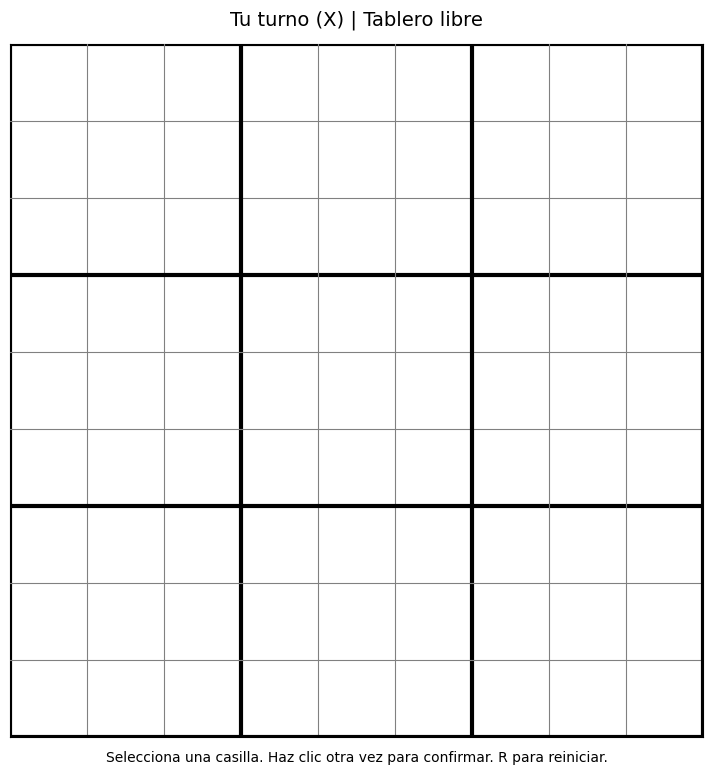

In [ ]:
# interfaz = InterfazGato(
#     modelo_ia=modelo_nuevo,
#     deterministic=True
# )

# plt.show()

## Interfaz IA vs P

Esta interfaz fue construida también por ChatGPT

In [ ]:
class InterfazGato:

    def __init__(self, modelo_ia=None, deterministic=True):

        # Si hay modelo, la IA juega como X.
        # Si no hay modelo, juegan dos personas.
        self.modelo_ia = modelo_ia
        self.deterministic = deterministic

        self.env = EntornoGato()
        self.env.reset()

        self.juego = self.env.juego

        self.decision_provisional = None
        self.terminado = False
        self.resultado = None

        self.mensaje = "Selecciona una casilla. R para reiniciar."

        self.fig, self.ax = plt.subplots(figsize=(9, 9))

        self.fig.canvas.mpl_connect(
            "button_press_event", self.click
        )
        self.fig.canvas.mpl_connect(
            "key_press_event", self.tecla
        )

        # La IA juega primero como X
        if self.modelo_ia is not None:
            self.jugar_ia()

        self.dibujar()

    # -----------------------------------------
    # Jugador que tiene el turno
    # -----------------------------------------

    def letra_actual(self):
        if self.env.agent_selection == "jugador 1":
            return 1
        return -1

    # -----------------------------------------
    # Previsualización de la jugada
    # -----------------------------------------

    def estado_provisional(self):

        if self.decision_provisional is None:
            return None

        prueba = copy.deepcopy(self.juego)

        turno, resultado = prueba.jugar_solo(
            self.decision_provisional
        )

        obligado = prueba.tablero.get_res_ultima_jugada()

        return obligado, resultado

    # -----------------------------------------
    # Revisar si terminó la partida
    # -----------------------------------------

    def revisar_final(self):

        agente = "jugador 1"

        if not (
            self.env.terminations[agente]
            or self.env.truncations[agente]
        ):
            return False

        self.terminado = True

        if self.juego.quien_gano_grande(1):
            self.resultado = 1
            self.mensaje = "¡Ganó X (IA)! Pulsa R para reiniciar."

        elif self.juego.quien_gano_grande(-1):
            self.resultado = -1
            self.mensaje = "¡Ganaste tú (O)! Pulsa R para reiniciar."

        elif self.juego.hubo_empate_grande():
            self.resultado = 999
            self.mensaje = "¡Empate general! Pulsa R para reiniciar."

        else:
            self.resultado = None
            self.mensaje = "Partida interrumpida."

        return True

    # -----------------------------------------
    # Turno de la IA (ahora juega X)
    # -----------------------------------------

    def jugar_ia(self):

        if self.terminado or self.modelo_ia is None:
            return

        if self.env.agent_selection != "jugador 1":
            return

        # Observación de X
        obs_X = self.env.observe("jugador 1")

        observacion = obs_X["observation"]
        mascara = obs_X["action_mask"].astype(bool)

        # La IA elige su jugada
        accion, _ = self.modelo_ia.predict(
            observacion,
            action_masks=mascara,
            deterministic=self.deterministic
        )

        accion = int(np.asarray(accion).item())

        if not mascara[accion]:
            raise RuntimeError("La IA eligió una acción ilegal")

        # Ejecutamos la jugada de X
        self.env.step(accion)

        tablero, casilla = divmod(accion, 9)

        if not self.revisar_final():
            self.mensaje = (
                f"La IA jugó en tablero {tablero + 1}, "
                f"casilla {casilla + 1}. Tu turno (O)."
            )

    # -----------------------------------------
    # Confirmar jugada humana (O)
    # -----------------------------------------

    def confirmar_jugada(self):

        if self.decision_provisional is None:
            return

        if self.terminado:
            return

        tablero, casilla = self.decision_provisional
        accion = 9 * tablero + casilla

        agente = self.env.agent_selection

        mascara = self.env.observe(agente)["action_mask"]

        if not mascara[accion]:
            self.mensaje = "La jugada ya no es legal."
            self.decision_provisional = None
            self.dibujar()
            return

        # Jugada de O
        self.env.step(accion)

        self.decision_provisional = None

        # Revisar si O ganó o empató
        if self.revisar_final():
            self.dibujar()
            return

        # Si hay IA, responde automáticamente como X
        if self.modelo_ia is not None:
            self.jugar_ia()
        else:
            self.mensaje = "Jugada realizada. Siguiente jugador."

        self.dibujar()

    # -----------------------------------------
    # Dibujar tablero
    # -----------------------------------------

    def dibujar(self):

        ax = self.ax
        ax.clear()

        ax.set_xlim(0, 9)
        ax.set_ylim(9, 0)
        ax.set_aspect("equal")

        ax.set_xticks([])
        ax.set_yticks([])

        # Líneas del tablero
        for i in range(10):

            ancho = 3 if i % 3 == 0 else 0.8
            color = "black" if i % 3 == 0 else "gray"

            ax.plot(
                [i, i], [0, 9],
                color=color, lw=ancho, zorder=5
            )

            ax.plot(
                [0, 9], [i, i],
                color=color, lw=ancho, zorder=5
            )

        # Dibujar las fichas
        for tablero in range(9):

            ft, ct = divmod(tablero, 3)

            for casilla in range(9):

                valor = self.juego.tablero.grilla[
                    tablero, casilla
                ]

                if valor not in (1, -1):
                    continue

                fc, cc = divmod(casilla, 3)

                ax.text(
                    ct * 3 + cc + 0.5,
                    ft * 3 + fc + 0.5,
                    "X" if valor == 1 else "O",
                    fontsize=25,
                    color=(
                        "royalblue"
                        if valor == 1 else "firebrick"
                    ),
                    ha="center",
                    va="center",
                    zorder=2
                )

        # Mostrar subtableros ganados o empatados
        for tablero, estado in enumerate(
            self.juego.tablero.estado_grande
        ):

            if estado == 0:
                continue

            ft, ct = divmod(tablero, 3)

            color = (
                "royalblue" if estado == 1 else
                "firebrick" if estado == -1 else
                "gray"
            )

            ax.add_patch(
                Rectangle(
                    (ct * 3, ft * 3),
                    3, 3,
                    facecolor=color,
                    alpha=0.12,
                    zorder=1
                )
            )

            simbolo = (
                "X" if estado == 1 else
                "O" if estado == -1 else
                "EMPATE"
            )

            ax.text(
                ct * 3 + 1.5,
                ft * 3 + 1.5,
                simbolo,
                fontsize=70 if estado != 999 else 15,
                color=color,
                alpha=0.4,
                weight="bold",
                ha="center",
                va="center",
                zorder=3
            )

        obligado = self.juego.tablero.get_res_ultima_jugada()

        # Jugada provisional del humano en gris
        if self.decision_provisional is not None:

            tablero, casilla = self.decision_provisional

            ft, ct = divmod(tablero, 3)
            fc, cc = divmod(casilla, 3)

            simbolo = (
                "X" if self.letra_actual() == 1 else "O"
            )

            ax.text(
                ct * 3 + cc + 0.5,
                ft * 3 + fc + 0.5,
                simbolo,
                fontsize=25,
                color="gray",
                alpha=0.65,
                ha="center",
                va="center",
                zorder=4
            )

            obligado, _ = self.estado_provisional()

        # Resaltar el tablero obligatorio
        if not self.terminado and obligado != 9:

            ft, ct = divmod(int(obligado), 3)

            ax.add_patch(
                Rectangle(
                    (ct * 3, ft * 3),
                    3, 3,
                    fill=False,
                    edgecolor="dodgerblue",
                    lw=5,
                    zorder=6
                )
            )

        # Título
        if self.terminado:

            if self.resultado == 999:
                titulo = "¡Empate general!"

            elif self.resultado in (1, -1):
                simbolo = "X" if self.resultado == 1 else "O"
                titulo = f"¡Ganó {simbolo}!"

            else:
                titulo = "Partida interrumpida"

        else:

            simbolo = (
                "X" if self.letra_actual() == 1 else "O"
            )

            if self.decision_provisional is not None:
                titulo = f"Jugada provisional de {simbolo}"

            elif self.modelo_ia is not None:
                titulo = "Tu turno (O)"

            else:
                titulo = f"Turno de {simbolo}"

            titulo += (
                " | Tablero libre" if obligado == 9
                else f" | Tablero {int(obligado) + 1}"
            )

        ax.set_title(titulo, fontsize=14, pad=14)

        ax.set_xlabel(
            self.mensaje,
            fontsize=10,
            labelpad=10
        )

        self.fig.canvas.draw_idle()

    # -----------------------------------------
    # Detectar clics
    # -----------------------------------------

    def click(self, event):

        if self.terminado or event.inaxes != self.ax:
            return

        if event.xdata is None or event.ydata is None:
            return

        # Si hay IA, el humano solo puede jugar como O
        if (
            self.modelo_ia is not None
            and self.env.agent_selection != "jugador 2"
        ):
            return

        x, y = event.xdata, event.ydata

        if not (0 <= x < 9 and 0 <= y < 9):
            return

        col, fila = int(x), int(y)

        tablero = 3 * (fila // 3) + col // 3
        casilla = 3 * (fila % 3) + col % 3

        decision = (tablero, casilla)
        accion = 9 * tablero + casilla

        agente = self.env.agent_selection

        mascara = self.env.observe(agente)["action_mask"]

        if not mascara[accion]:
            self.mensaje = (
                "Movimiento inválido: "
                "selecciona una casilla permitida."
            )
            self.dibujar()
            return

        # Segundo clic: confirmar
        if self.decision_provisional == decision:
            self.confirmar_jugada()
            return

        # Primer clic: previsualizar
        self.decision_provisional = decision

        self.mensaje = (
            "Jugada provisional en gris. "
            "Haz clic otra vez para confirmar."
        )

        self.dibujar()

    # -----------------------------------------
    # Atajos de teclado
    # -----------------------------------------

    def tecla(self, event):

        if event.key == "r":

            self.env.reset()
            self.juego = self.env.juego

            self.decision_provisional = None
            self.terminado = False
            self.resultado = None

            self.mensaje = "Nueva partida."

            # La IA vuelve a jugar primero como X
            if self.modelo_ia is not None:
                self.jugar_ia()

            self.dibujar()

        elif event.key in ("enter", "return"):
            self.confirmar_jugada()

        elif event.key == "escape":

            self.decision_provisional = None
            self.mensaje = "Jugada provisional cancelada."

            self.dibujar()

    def cerrar(self):
        self.env.close()
        plt.close(self.fig)


In [ ]:

# modelo_nuevo = MaskablePPO.load(
#     r"C:\Users\HP\Desktop\Univeridad\10 semestre\Simulación Estocástica\Proyecto\guagua_18.zip"
# )
# interfaz = InterfazGato(
#     modelo_ia=modelo_nuevo,
#     deterministic=True
# )

# plt.show()